In [ ]:
# Purpose:
#   Generate publication-ready cohort, metadata, and immune landscape figures
#   from the fully annotated PBMC scRNA-seq + imputed ADT dataset.
#
# Summary:
#   - Define plotting parameters (fonts, DPI, line widths)
#   - Load patient-level metadata and construct race–disease composite variables
#   - Summarize and test age distributions across race_stage groups
#   - Visualize patient metadata (disease state, age, diabetes, obesity) as row-annotated panels
#   - Load finalized, level-3–annotated PBMC AnnData object
#   - Define consistent color palettes for all immune cell subtypes
#   - Generate global and split UMAPs colored by immune cell identity and race_stage
#   - Quantify and export per-patient immune cell-type proportions
#   - Visualize PBMC composition across patients using stacked bar plots
#   - Assess QC metrics (gene count, UMI, mitochondrial %, Azimuth scores) by cell type
#   - Integrate imputed ADT expression into AnnData metadata
#   - Visualize protein markers across major immune lineages on UMAP
#   - Create shared legends and reusable visualization utilities for manuscript figures

# Header

In [1]:
from utils import *

In [2]:
from matplotlib.lines import Line2D

In [3]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [4]:
os.chdir('../')

# Meta data

In [5]:
color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'

}

binary_color = {'Y': 'navy', 'N': '#CCCCCC'}

In [6]:
meta = pd.read_csv('data/01_meta/meta_pt.csv')

meta['race_stage'] = meta['race'] + '-' + meta['group']
meta['race_stage'] = pd.Categorical(meta['race_stage'], categories=list(color_set.keys()), ordered=True)

# Order by race_stage, then age
meta = meta.sort_values(['race_stage', 'age'])

meta

,sampleid,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage,race_stage
10,43-H,Pool137_14,1,91,HRL,NHW,42.5,N,Y,NHW-HRL,NHW-HRL
23,956-H,Pool138_15,2,89,HRL,NHW,42.8,N,N,NHW-HRL,NHW-HRL
22,568-H,Pool138_14,2,93,HRL,NHW,43.7,N,N,NHW-HRL,NHW-HRL
14,42-H,Pool137_26,1,91,HRL,NHW,53.1,N,N,NHW-HRL,NHW-HRL
20,63-H,Pool138_9,2,98,HRL,NHW,57.7,N,Y,NHW-HRL,NHW-HRL
13,36-H,Pool137_25,1,90,HRL,NHW,59.6,N,N,NHW-HRL,NHW-HRL
15,61-H,Pool137_29,1,90,HRL,NHW,59.6,N,N,NHW-HRL,NHW-HRL
19,24-H,Pool138_4,2,94,HRL,NHW,60.5,N,Y,NHW-HRL,NHW-HRL
9,1-H,Pool137_10,1,88,HRL,NHW,62.3,N,N,NHW-HRL,NHW-HRL
8,6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL,NHW-HRL


In [20]:
# pip install tableone  # if needed

from tableone import TableOne
import pandas as pd
import numpy as np
from scipy import stats

meta2 = meta[['race_stage','age']].copy()
meta2 = meta2.dropna(subset=['race_stage', 'age'])
meta2['race_stage'] = meta2['race_stage'].astype(str)
meta2['age'] = pd.to_numeric(meta2['age'], errors='coerce')

print(meta2.shape)

# Summary: mean±sd and median[IQR] by group
tab = meta2.groupby('race_stage')['age'].agg(
    n='count',
    mean='mean',
    sd='std',
    median='median',
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75),
).reset_index()

tab['mean (sd)'] = tab.apply(lambda r: f"{r['mean']:.1f} ({r['sd']:.1f})", axis=1)
tab['median [IQR]'] = tab.apply(lambda r: f"{r['median']:.1f} [{r['q1']:.1f}, {r['q3']:.1f}]", axis=1)

tab_out = tab[['race_stage', 'n', 'mean (sd)', 'median [IQR]']]

# Test difference across race_stage groups (Kruskal-Wallis is safe)
# groups = [g['age'].dropna().values for _, g in meta2.groupby('race_stage')]
# H, p = stats.kruskal(*groups)

print(tab_out.to_string(index=False))
# print(f"\nKruskal–Wallis p-value for age across race_stage: {p:.3g}")

from scipy.stats import f_oneway

F, p_anova = f_oneway(*groups)
print(f"ANOVA p-value: {p_anova:.3g}")

(55, 2)
race_stage  n   mean (sd)      median [IQR]
    NHB-BC 13 55.6 (18.1) 54.0 [45.0, 69.0]
  NHB-DCIS  4 54.2 (18.1) 49.0 [43.5, 59.8]
   NHB-HRL 10  57.0 (8.8) 59.9 [49.8, 62.9]
    NHW-BC 12 57.5 (14.3) 64.5 [45.5, 67.0]
  NHW-DCIS  6 53.2 (14.9) 49.0 [44.2, 59.8]
   NHW-HRL 10  55.3 (9.6) 58.7 [46.1, 60.3]
ANOVA p-value: 0.991


In [10]:
Counter(meta['race_stage'])

Counter({'NHB-BC': 13,
         'NHW-BC': 12,
         'NHW-HRL': 10,
         'NHB-HRL': 10,
         'NHW-DCIS': 6,
         'NHB-DCIS': 4})

In [7]:
meta['age'].describe()

count    55.000000
mean     55.850909
std      13.540035
min      31.000000
25%      44.750000
50%      57.700000
75%      64.950000
max      86.000000
Name: age, dtype: float64

In [24]:
meta.groupby(['diabetes','obesity']).size()

diabetes  obesity
N         N          30
          Y          16
Y         N           6
          Y           3
dtype: int64

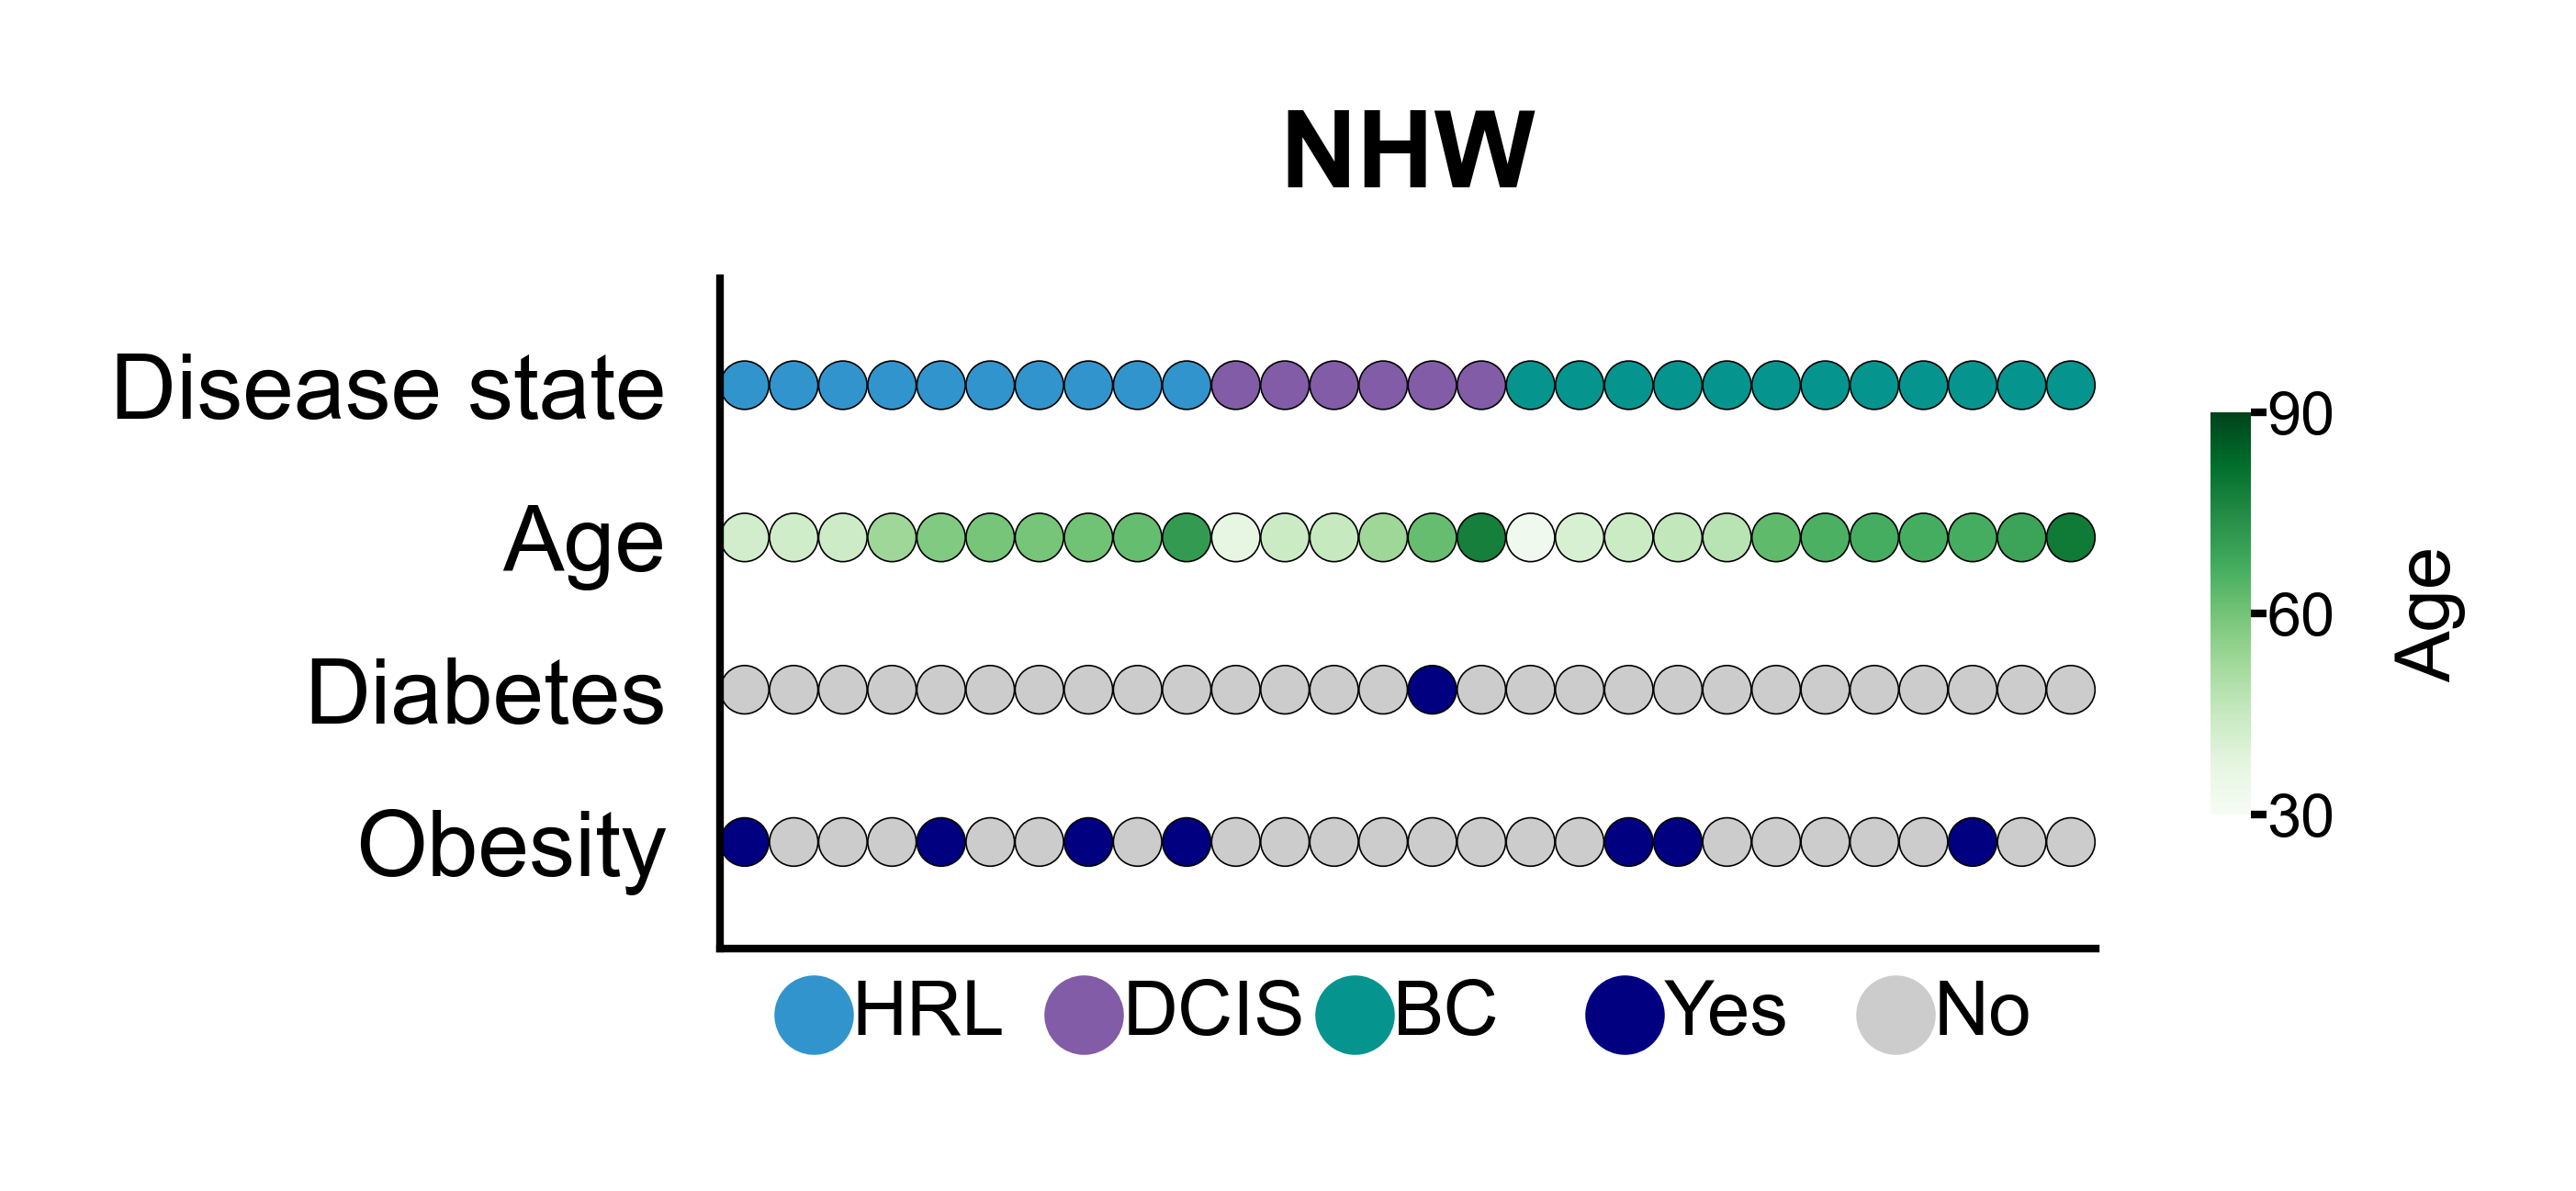

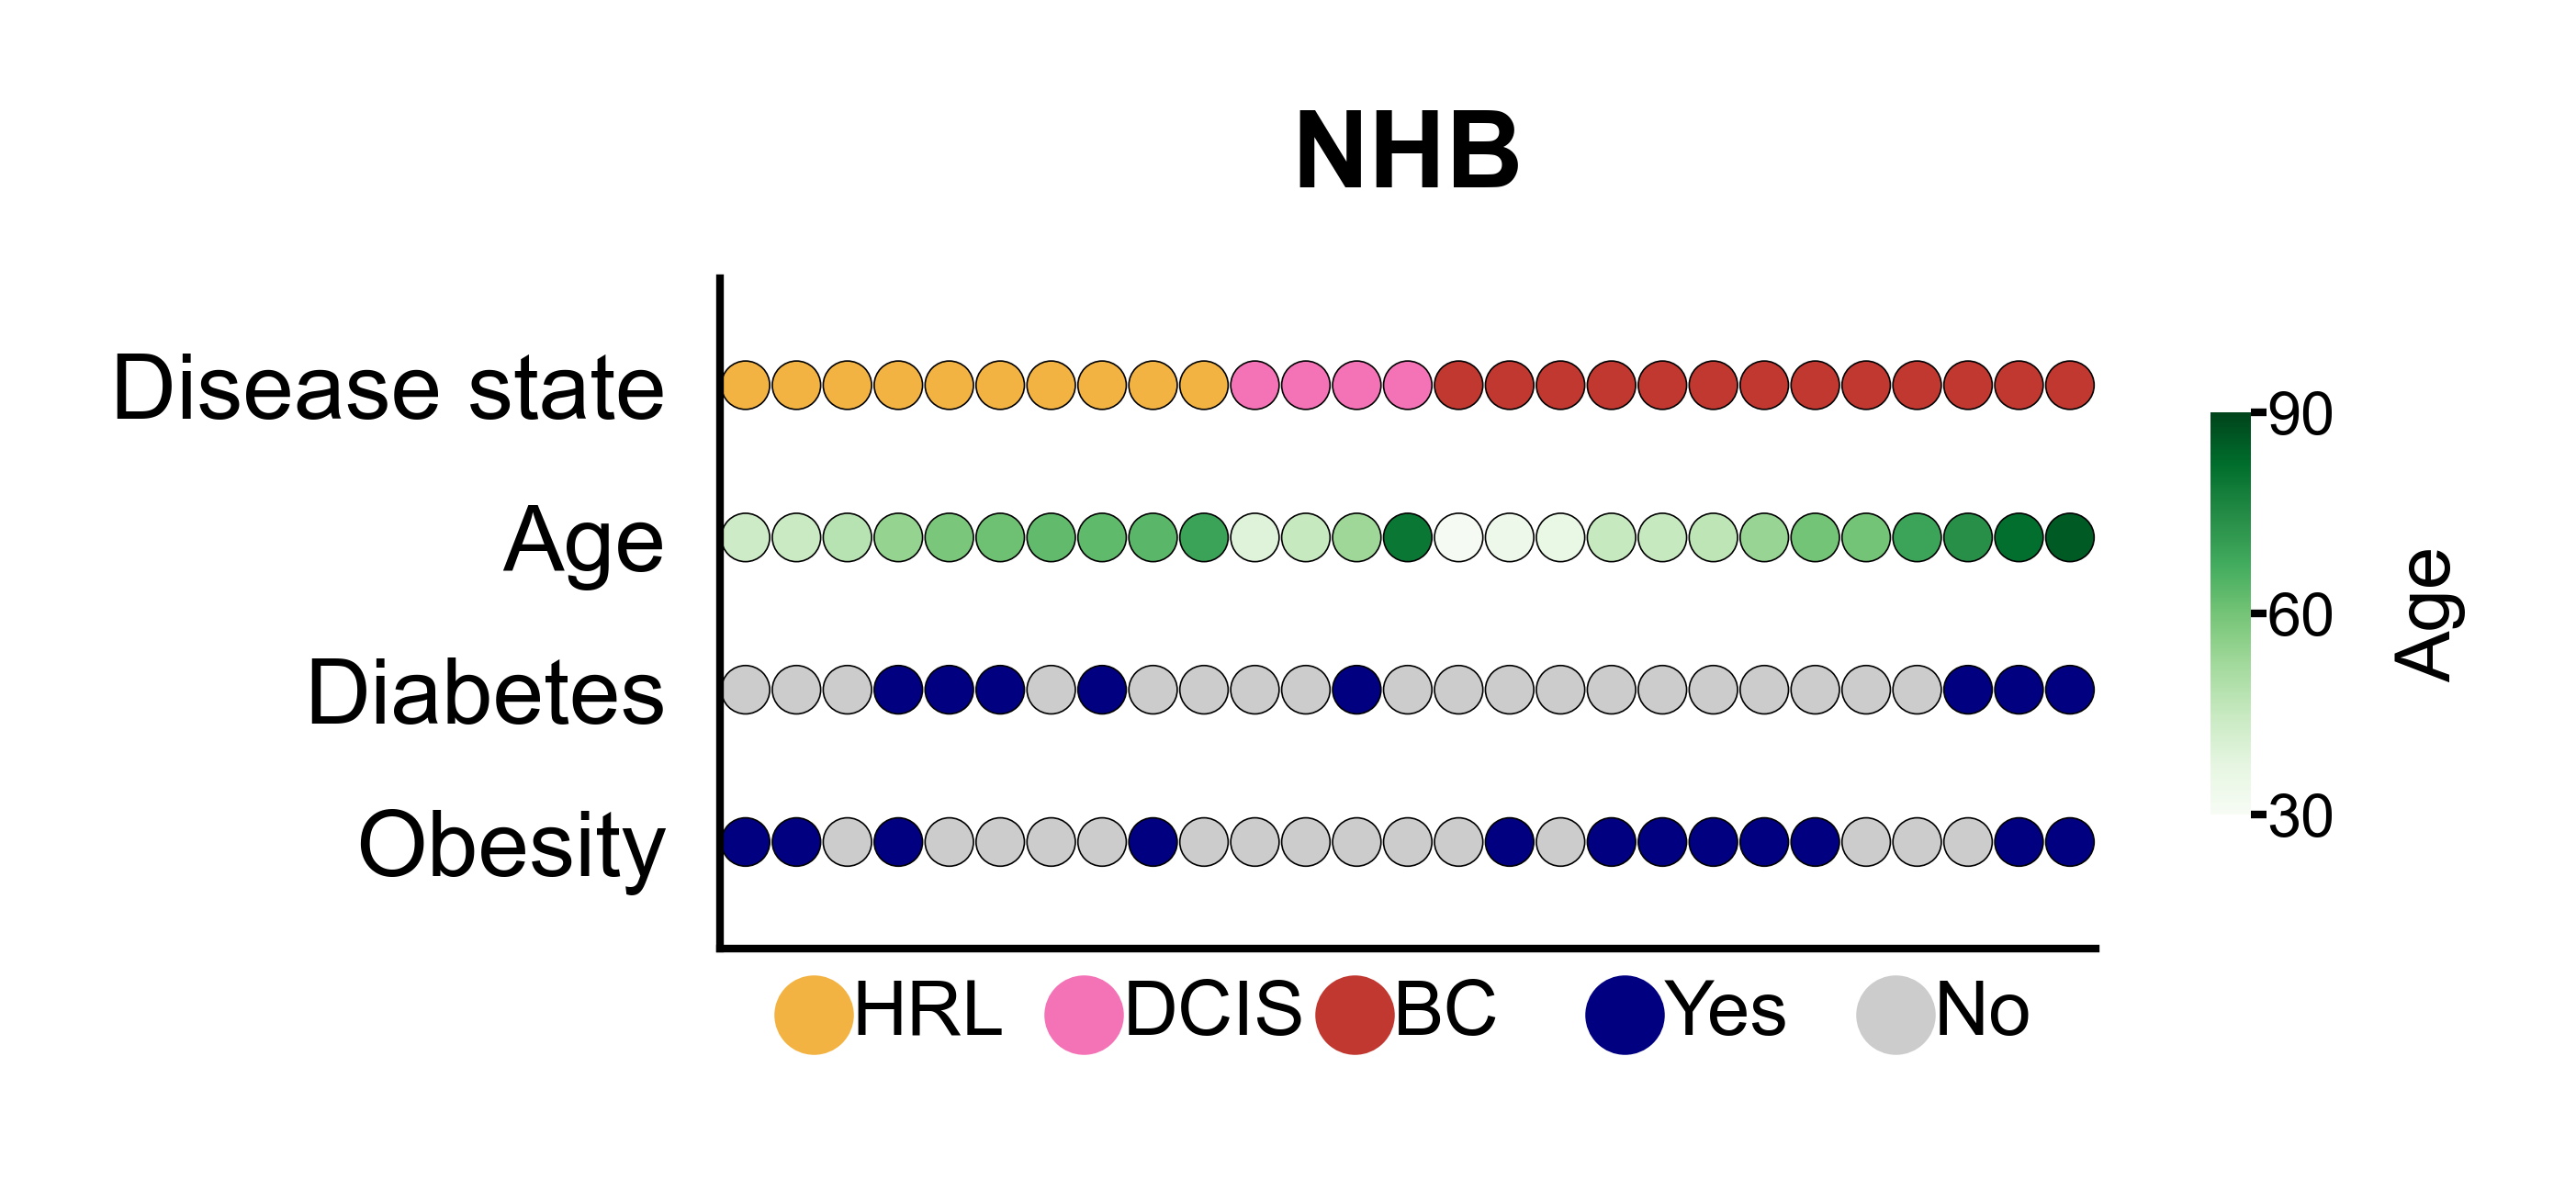

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --------------------
# Split data
# --------------------
meta_nhw = meta[meta['race'] == 'NHW'].sort_values(['race_stage', 'age'])
meta_nhb = meta[meta['race'] == 'NHB'].sort_values(['race_stage', 'age'])

# --------------------
# Row color builder
# --------------------
def make_rows(meta_sub):
    race_colors = meta_sub['race_stage'].map(color_set)
    age_colors = sns.color_palette("Greens", as_cmap=True)(
        (meta_sub['age'] - 30) / 60
    )
    diabetes_colors = meta_sub['diabetes'].map(binary_color)
    obesity_colors  = meta_sub['obesity'].map(binary_color)
    return [race_colors, age_colors, diabetes_colors, obesity_colors]

# --------------------
# Plot function (single panel)
# --------------------
def plot_meta_panel(meta_sub, race, fname):
    rows = make_rows(meta_sub)
    yticks = ['Obesity', 'Diabetes', 'Age', 'Disease state']

    fig, ax = plt.subplots(figsize=(1.6, .8))

    for i, row in enumerate(rows[::-1]):
        ax.scatter(
            np.arange(len(meta_sub)),
            [i] * len(meta_sub),
            c=row, s=10, edgecolors='k', linewidths=0.1
        )

    ax.set_yticks(range(4))
    ax.set_yticklabels(yticks, fontsize=6)
    ax.set_xlim(-0.5, len(meta_sub) - 0.5)
    ax.set_ylim(-0.7, 3.7)
    ax.set_xticks([])
    ax.set_title(race, fontsize=7, weight='bold')
    ax.tick_params(left=False, bottom=False)
    sns.despine(ax=ax)

    # age colorbar
    cax = inset_axes(ax, width="3%", height="60%", loc='center left',
                     bbox_to_anchor=(1.05, 0, 1, 1), bbox_transform=ax.transAxes)
    sm = plt.cm.ScalarMappable(cmap=plt.cm.Greens, norm=Normalize(30, 90))
    cb = plt.colorbar(sm, cax=cax)
    cb.set_ticks([30, 60, 90])
    cb.ax.tick_params(labelsize=4, length=1)
    cb.set_label('Age', fontsize=5)
    cb.outline.set_visible(False)

    # legend
    stage_keys = [f'{race}-HRL', f'{race}-DCIS', f'{race}-BC']
    labels = ['HRL', 'DCIS', 'BC', 'Yes', 'No']
    colors = (
        [color_set[k] for k in stage_keys] +
        [binary_color['Y'], binary_color['N']]
    )

    lax = fig.add_axes([0.2, 0, 0.8, 0.15])
    lax.axis('off')
    spacing = 1.4
    for i, (lab, col) in enumerate(zip(labels, colors)):
        x = i * spacing
        lax.scatter(x, 0, s=22, color=col)
        lax.text(x + 0.2, 0, lab, fontsize=5, va='center')
    lax.set_xlim(-0.3, spacing * len(labels))

    plt.savefig(fname, dpi=600, bbox_inches='tight')
    plt.show()

# --------------------
# Run separately
# --------------------
plot_meta_panel(meta_nhw, 'NHW', 'plots/F1/pt_meta_NHW.png')
plot_meta_panel(meta_nhb, 'NHB', 'plots/F1/pt_meta_NHB.png')

# sc UMAP

In [26]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)
dat

AnnData object with n_obs × n_vars = 434565 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standardized', 'vf_vst_counts.Pool137_11_variable', 'vf_vst_counts.Pool137

In [28]:
tmp = dat.obs[['celltype_level3','dataset_name']].drop_duplicates()

Counter(tmp['celltype_level3'])

Counter({'Naive CD4T': 55,
         'Nonclassical Monocyte': 55,
         'CD56-dim NK': 55,
         'Naive B': 55,
         'Central Memory CD4T': 55,
         'Classical Monocyte': 55,
         'Cytotoxic Monocyte': 55,
         'Cytotoxic CD4T': 55,
         'Effector Memory CD4T': 55,
         'Intermediate Monocyte': 55,
         'Effector Memory CD8T': 55,
         'Treg': 55,
         'pDC': 55,
         'Mature B': 55,
         'Memory B': 55,
         'Central Memory CD8T': 55,
         'Naive CD8T': 54,
         'cDC2': 54,
         'CD56-bright NK': 54,
         'cDC1': 54,
         'Proliferating NK': 54,
         'Plasmablast': 53,
         'MAIT': 52,
         'Double Negative T': 46,
         'γδ T': 40})

In [9]:
print(len(dat.obs['dataset_name'].unique()))

55


In [43]:
cells_ordered = [
    'Naive B','Mature B','Memory B','Plasmablast',
    'Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
    'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
    'Double Negative T','γδ T','MAIT',
    'cDC1','cDC2','pDC',
    'Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte',
    'CD56-dim NK','CD56-bright NK','Proliferating NK'
]



In [44]:
import colorcet as cc
import seaborn as sns

plt25 = sns.color_palette(cc.glasbey_bw_minc_20, n_colors=25)
sns.palplot(plt25)

In [45]:
celltype_palette = dict(zip(cells_ordered, plt25))

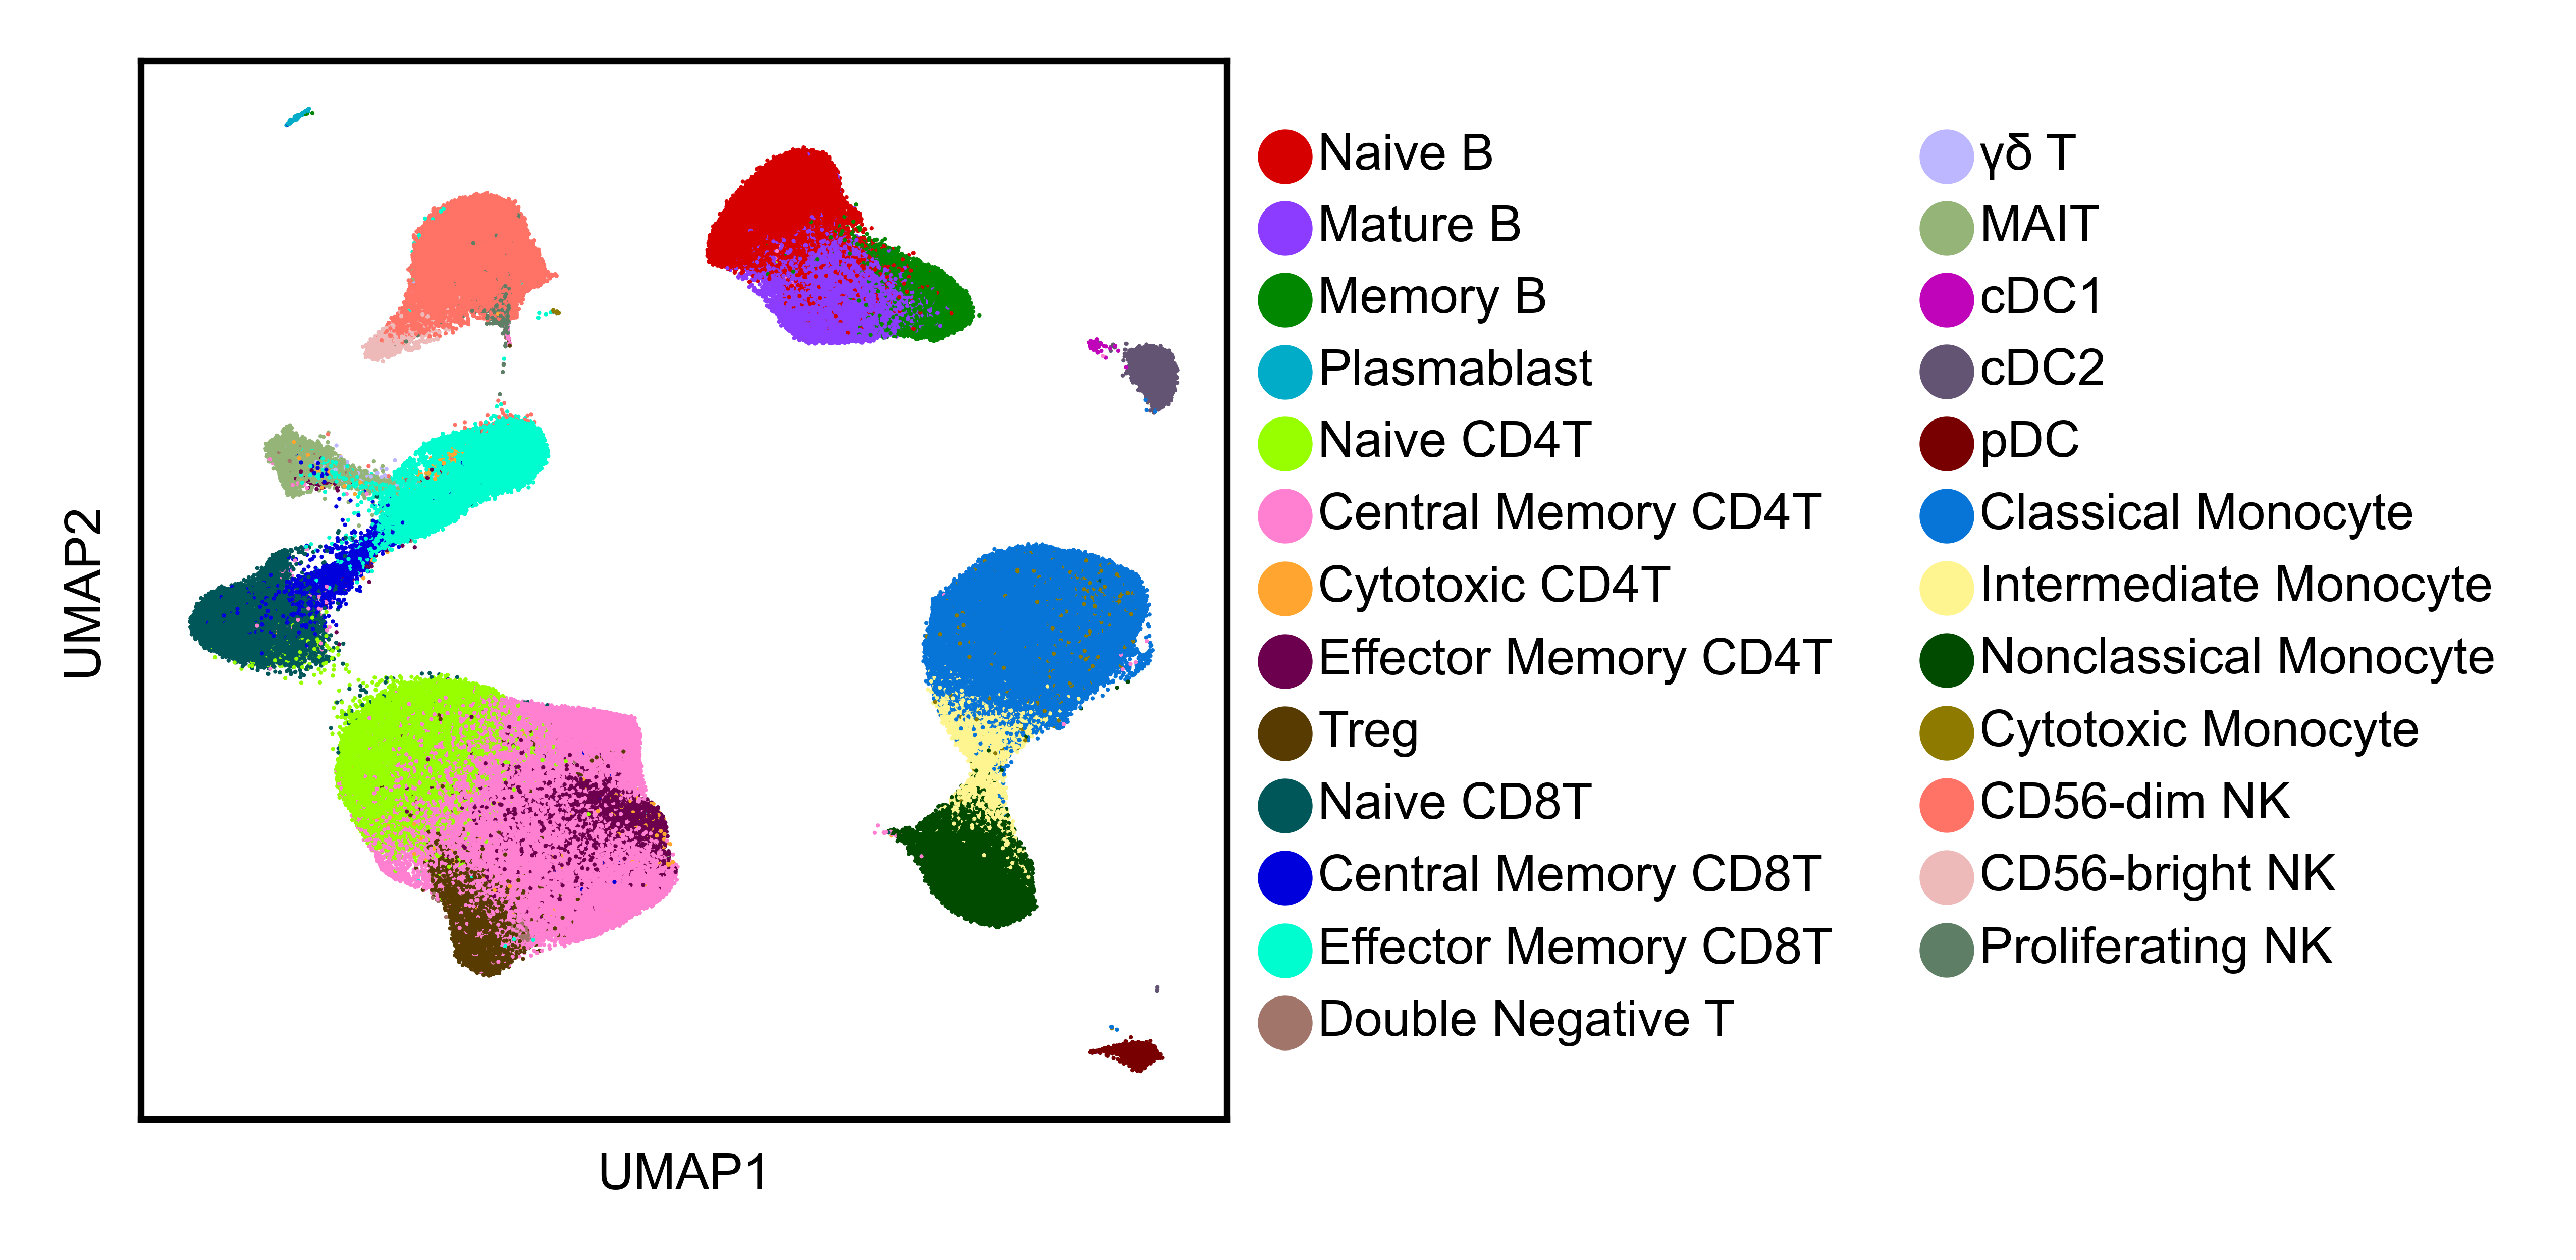

In [47]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/F1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none', # Keeps text as font
    
    'font.size': 6,  # 5–7 pt as per guidelines
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,

    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    
    'figure.dpi': 600
})


palette = [celltype_palette[x] for x in dat.obs['celltype_level3'].cat.categories]

sc.settings._vector_friendly = True
with rc_context({"figure.figsize": (2.3, 2.3)}):
    
    sc.pl.umap(dat, color=['celltype_level3'], 
               title='',
               s=1, 
               frameon=True, 
               ncols=1, 
               palette = palette,
               save='celltype_level3.svg'
              )

# Stacked bar by patient

In [51]:
meta

,sampleid,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage,race_stage
10,43-H,Pool137_14,1,91,HRL,NHW,42.5,N,Y,NHW-HRL,NHW-HRL
23,956-H,Pool138_15,2,89,HRL,NHW,42.8,N,N,NHW-HRL,NHW-HRL
22,568-H,Pool138_14,2,93,HRL,NHW,43.7,N,N,NHW-HRL,NHW-HRL
14,42-H,Pool137_26,1,91,HRL,NHW,53.1,N,N,NHW-HRL,NHW-HRL
20,63-H,Pool138_9,2,98,HRL,NHW,57.7,N,Y,NHW-HRL,NHW-HRL
13,36-H,Pool137_25,1,90,HRL,NHW,59.6,N,N,NHW-HRL,NHW-HRL
15,61-H,Pool137_29,1,90,HRL,NHW,59.6,N,N,NHW-HRL,NHW-HRL
19,24-H,Pool138_4,2,94,HRL,NHW,60.5,N,Y,NHW-HRL,NHW-HRL
9,1-H,Pool137_10,1,88,HRL,NHW,62.3,N,N,NHW-HRL,NHW-HRL
8,6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL,NHW-HRL


In [50]:
dat.obs#.columns

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [54]:
meta_cells = pd.merge(
    dat.obs, meta, 
    on='dataset_name', how='left'
)
meta_cells.index = dat.obs.index
meta_cells

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race-stage,race_stage
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL,NHW-HRL
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL,NHW-HRL
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL,NHW-HRL
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL,NHW-HRL
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL,NHW-HRL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,63-H,2,98,HRL,NHW,57.7,N,Y,NHW-HRL,NHW-HRL
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,63-H,2,98,HRL,NHW,57.7,N,Y,NHW-HRL,NHW-HRL
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,63-H,2,98,HRL,NHW,57.7,N,Y,NHW-HRL,NHW-HRL
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,63-H,2,98,HRL,NHW,57.7,N,Y,NHW-HRL,NHW-HRL


In [55]:
dat.obs = meta_cells

In [56]:
# Ensure categorical order for cell types
celltypes = dat.obs['celltype_level3'].cat.categories
palette = [celltype_palette[x] for x in celltypes]

# Patient metadata (one row per patient)
patient_meta = (
    dat.obs[['sampleid', 'race_stage', 'age']]
    .drop_duplicates()
    .sort_values(['race_stage', 'age'])
)

patient_order = patient_meta['sampleid'].tolist()

In [58]:
# Count cells per patient × celltype
ct_counts = (
    dat.obs
      .groupby(['sampleid', 'celltype_level3'])
      .size()
      .unstack(fill_value=0)
)

# Convert to proportions
ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)

# Reorder patients and cell types
ct_props = ct_props.loc[patient_order, celltypes]

ct_props

/tmp/ipykernel_2794519/1649854817.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['sampleid', 'celltype_level3'])


,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Cytotoxic CD4T,Effector Memory CD4T,Treg,Naive CD8T,...,cDC1,cDC2,pDC,Classical Monocyte,Intermediate Monocyte,Nonclassical Monocyte,Cytotoxic Monocyte,CD56-dim NK,CD56-bright NK,Proliferating NK
sampleid,,,,,,,,,,,,,,,,,,,,,
43-H,0.070151,0.037312,0.011674,0.001418,0.179577,0.206306,0.002182,0.028148,0.024220,0.072660,...,0.000109,0.011564,0.005782,0.138010,0.008182,0.014619,0.004364,0.115317,0.009492,0.001527
956-H,0.014172,0.043600,0.016339,0.000903,0.161943,0.159054,0.002166,0.025636,0.015075,0.071222,...,0.000632,0.010561,0.009478,0.249684,0.019408,0.058404,0.002708,0.043329,0.007853,0.000722
568-H,0.078019,0.029102,0.016409,0.004747,0.183695,0.157688,0.000929,0.025284,0.014138,0.071723,...,0.000000,0.008153,0.004644,0.213416,0.019505,0.034469,0.001032,0.060888,0.006708,0.001651
42-H,0.032960,0.047433,0.011409,0.000845,0.145362,0.165434,0.001796,0.028417,0.011832,0.026410,...,0.000634,0.017536,0.003592,0.291147,0.023769,0.031481,0.003486,0.062011,0.007817,0.000528
63-H,0.053535,0.034138,0.017457,0.000485,0.133450,0.266996,0.001455,0.051886,0.018718,0.016099,...,0.000485,0.008244,0.004946,0.112210,0.008244,0.014451,0.002910,0.048007,0.002328,0.000873
36-H,0.027157,0.101278,0.023802,0.001278,0.111342,0.175240,0.003355,0.043131,0.011342,0.028115,...,0.000479,0.029393,0.009425,0.268690,0.036102,0.055272,0.015974,0.026198,0.004633,0.001438
61-H,0.063164,0.029163,0.014783,0.002553,0.113291,0.125521,0.005913,0.013036,0.006585,0.058729,...,0.001478,0.034404,0.008198,0.289880,0.038973,0.077275,0.026341,0.043543,0.003360,0.000941
24-H,0.092120,0.013315,0.012681,0.001359,0.197917,0.238043,0.001993,0.035417,0.023732,0.031069,...,0.002083,0.015217,0.004620,0.162591,0.012047,0.022011,0.007518,0.061141,0.007518,0.000815
1-H,0.018101,0.007835,0.003647,0.000810,0.170066,0.213292,0.001621,0.021883,0.011617,0.034986,...,0.001351,0.019452,0.006079,0.217750,0.022153,0.054437,0.003512,0.130488,0.005673,0.002972


In [60]:
ct_props.to_csv('data/Tables/Supplemental Table 2.csv')

/tmp/ipykernel_3170860/706337919.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['sampleid', 'celltype_level3'])


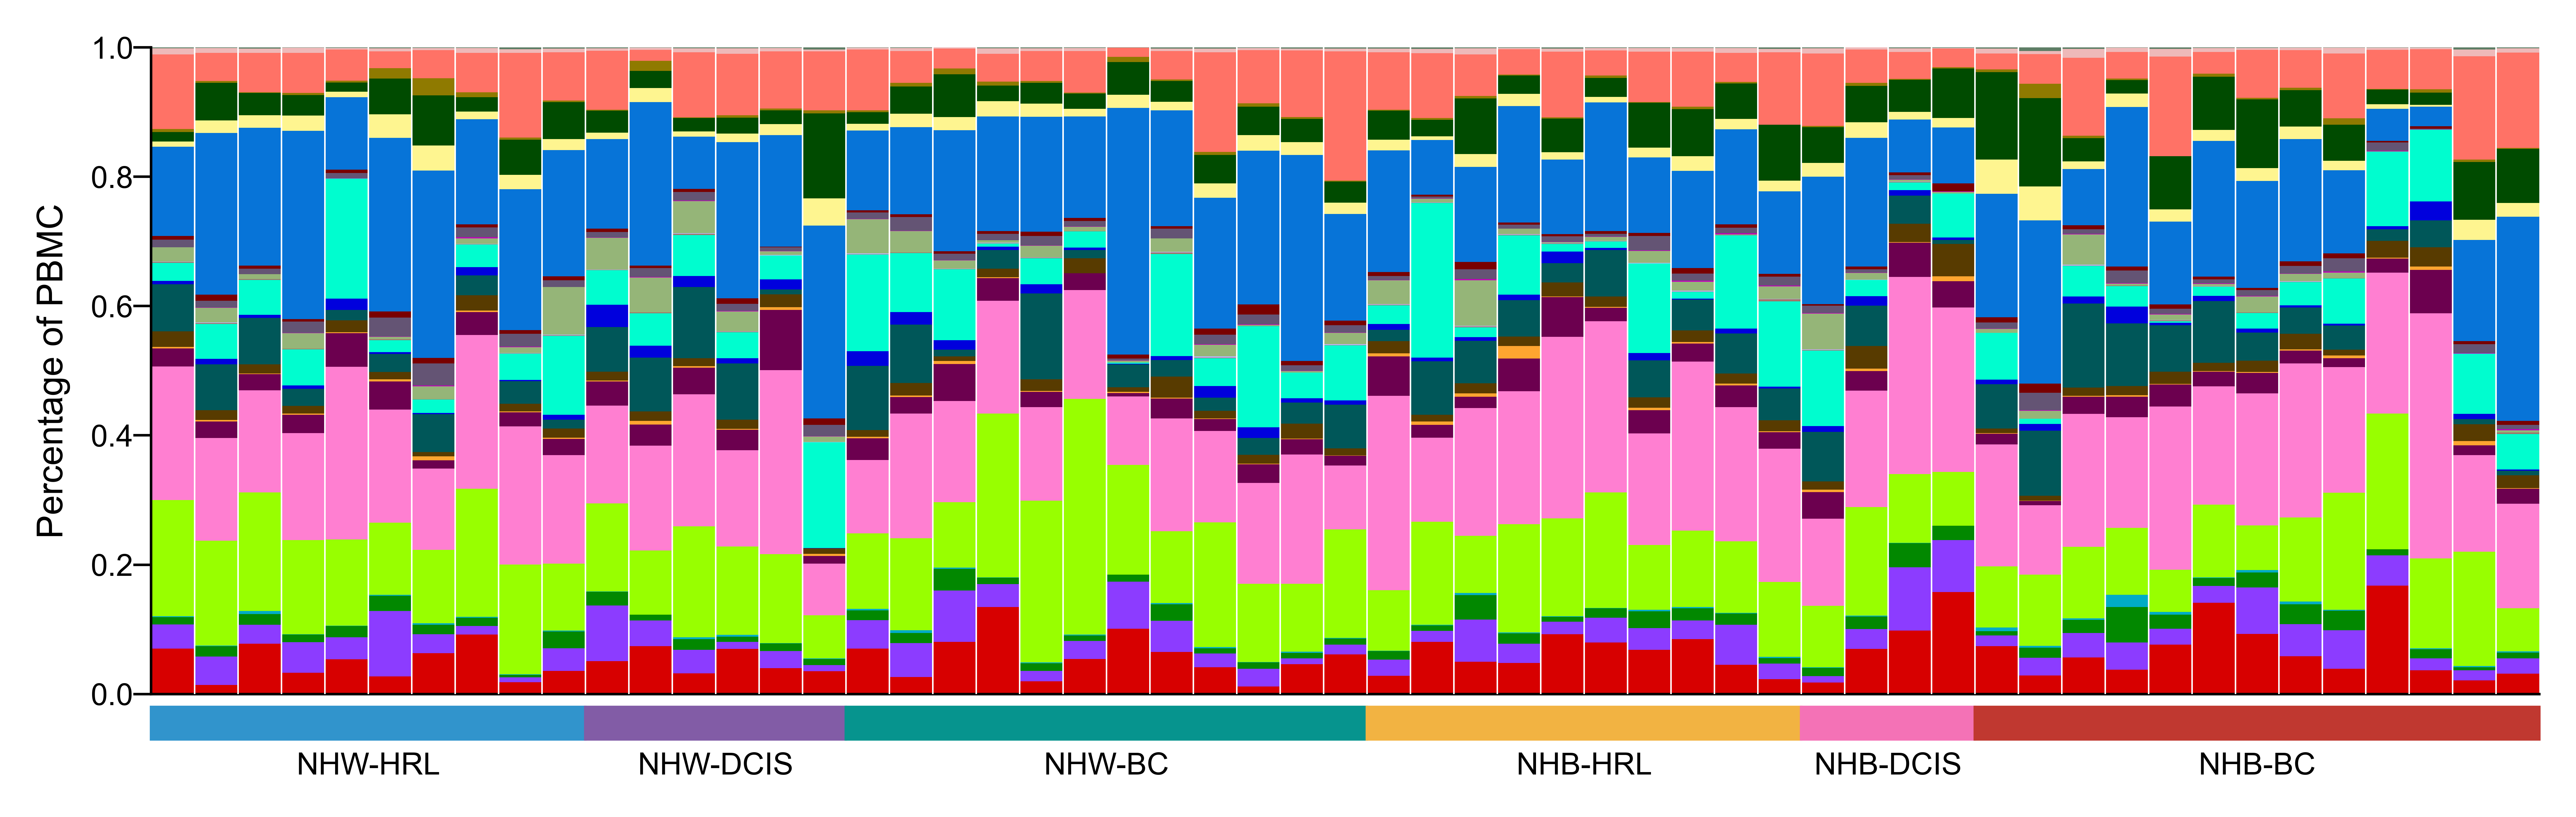

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist

# -------------------------
# Color definitions
# -------------------------
color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',
    'Diabetes':'navy',
    'Obesity':'salmon'
}

celltypes = dat.obs['celltype_level3'].cat.categories
palette = [celltype_palette[x] for x in celltypes]

# -------------------------
# Cell-type proportions per patient
# -------------------------
ct_counts = (
    dat.obs
       .groupby(['sampleid', 'celltype_level3'])
       .size()
       .unstack(fill_value=0)
)

ct_props = ct_counts.div(ct_counts.sum(axis=1), axis=0)

# -------------------------
# Patient metadata
# -------------------------
meta = (
    dat.obs[['sampleid', 'race_stage','age']]
    .drop_duplicates()
    .set_index('sampleid')
)

# -------------------------
# Order patients:
#   1) group by race_stage
#   2) within each group, cluster by composition
# -------------------------
ordered_patients = []

for rs in ['NHW-HRL','NHW-DCIS','NHW-BC',
           'NHB-HRL','NHB-DCIS','NHB-BC'
          ]:
    pts = meta.index[meta['race_stage'] == rs]

    # sort patients within race_stage by age
    order = (
        meta.loc[pts]
            .sort_values('age')
            .index
    )

    ordered_patients.extend(order)

ct_props = ct_props.loc[ordered_patients]
meta = meta.loc[ordered_patients]

# -------------------------
# Plot stacked bars
# -------------------------
fig, ax = plt.subplots(figsize=(7, 2.2))

bottom = np.zeros(len(ct_props))

for ct, col in zip(celltypes, palette):
    ax.bar(
        np.arange(len(ct_props)),
        ct_props[ct].values,
        bottom=bottom,
        color=col,
        width=1.0,
        edgecolor='none'
    )
    bottom += ct_props[ct].values

for x in np.arange(len(ct_props) - 1):
    ax.axvline(
        x + 0.5,
        color='white',
        linewidth=0.3,
        zorder=3
    )    

ax.set_ylim(0, 1)
ax.set_xlim(-0.5, len(ct_props) - 0.5)
ax.set_ylabel('Percentage of PBMC', fontsize=7)
ax.set_xticks([])
ax.tick_params(axis='y', labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

# -------------------------
# Bottom race_stage annotation bar
# -------------------------
y0 = -0.07
h  = 0.05

for rs, color in color_set.items():
    idx = np.where(meta['race_stage'] == rs)[0]
    if len(idx) == 0:
        continue
    ax.add_patch(
        plt.Rectangle(
            (idx.min() - 0.5, y0),
            len(idx),
            h,
            color=color,
            clip_on=False
        )
    )
    ax.text(
        idx.mean(),
        y0 - 0.02,
        rs,
        ha='center',
        va='top',
        fontsize=6,
        rotation=0
    )

plt.tight_layout()
plt.savefig('plots/F1/cell_prop_pt.svg')
plt.show()

# UMAP split by disease-race group
https://github.com/scverse/scanpy/issues/2333

In [53]:
dat.obs[['dataset_name']].head(3)

,dataset_name
Pool137_10_AAACCTGAGACTCGGA-1,Pool137_10
Pool137_10_AAACCTGAGATCTGCT-1,Pool137_10
Pool137_10_AAACCTGAGATTACCC-1,Pool137_10


In [54]:
meta.head(3)

,sampleid,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race_stage
10,43-H,Pool137_14,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
23,956-H,Pool138_15,2,89,HRL,NHW,42.8,N,N,NHW-HRL
22,568-H,Pool138_14,2,93,HRL,NHW,43.7,N,N,NHW-HRL


In [55]:
meta_indexed = meta.set_index('dataset_name')

cols_to_add = ['sampleid','batch','group','race','age','diabetes','obesity','race_stage']

for col in cols_to_add:
    dat.obs[col] = dat.obs['dataset_name'].map(meta_indexed[col])


In [56]:
ordered_name = [
    'NHW-HRL', 'NHW-DCIS', 'NHW-BC',
    'NHB-HRL', 'NHB-DCIS', 'NHB-BC'
]

dat.obs['race_stage'] = pd.Categorical(
   dat.obs['race_stage'], 
   categories=ordered_name, 
    ordered=True
)

In [67]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def split_umap(
    adata, split_by, color=None, palette=None, ncol=2, nrow=None, legend_labels=None, legend_title=None, save=None, **kwargs
):
    categories = [    
        'NHW-HRL', 'NHB-HRL', 
        'NHW-DCIS', 'NHB-DCIS', 
        'NHW-BC','NHB-BC'
]#adata.obs[split_by].cat.categories

    if nrow is None:
        nrow = int(np.ceil(len(categories) / ncol))

    fig, axs = plt.subplots(nrow, ncol, figsize=(1.1 * ncol, 1.1 * nrow), sharex=True, sharey=True)
    axs = axs.flatten()

    # Plot each split panel (no legends on panels)
    for i, cat in enumerate(categories):
        ax = axs[i]
        subset = adata[adata.obs[split_by] == cat].copy()
        sc.pl.umap(
            subset,
            color=color,
            ax=ax,
            show=False,
            title='',
            legend_loc=None,
            palette=palette,
            **kwargs
        )
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.set_title(str(cat), fontsize=6, pad=1)
        
    # Hide unused axes
    for j in range(i + 1, len(axs)):
        axs[j].set_visible(False)

    # --- Shared legend (based on FULL adata.obs) ---
    if color is not None and palette is not None:
        all_vals = adata.obs[color[0]].cat.categories if hasattr(adata.obs[color[0]], "cat") else np.unique(adata.obs[color[0]])
        handles = [
            Line2D([0], [0], marker='o', color='w',
                   markerfacecolor=palette.get(val, '#999999'),
                   markeredgecolor='none', markersize=5,
                   label=legend_labels.get(val, val) if legend_labels else val)
            for val in all_vals
        ]
        leg = fig.legend(
            handles=handles,
            loc='center left',
            bbox_to_anchor=(0.92, 0.5),
            title=None,#legend_title if legend_title else color[0],
            fontsize=5,
            title_fontsize=8,
            borderaxespad=0.2,
            frameon=False  # << removes the box!
        )
    

    plt.tight_layout(rect=[0, 0, 0.95, 1])
    if save is not None:
        plt.savefig(save, format='svg', bbox_inches='tight')
    plt.show()
# Example usage:
# split_umap(dat, color=['celltype_level3'], split_by='type', palette=celltype_palette)

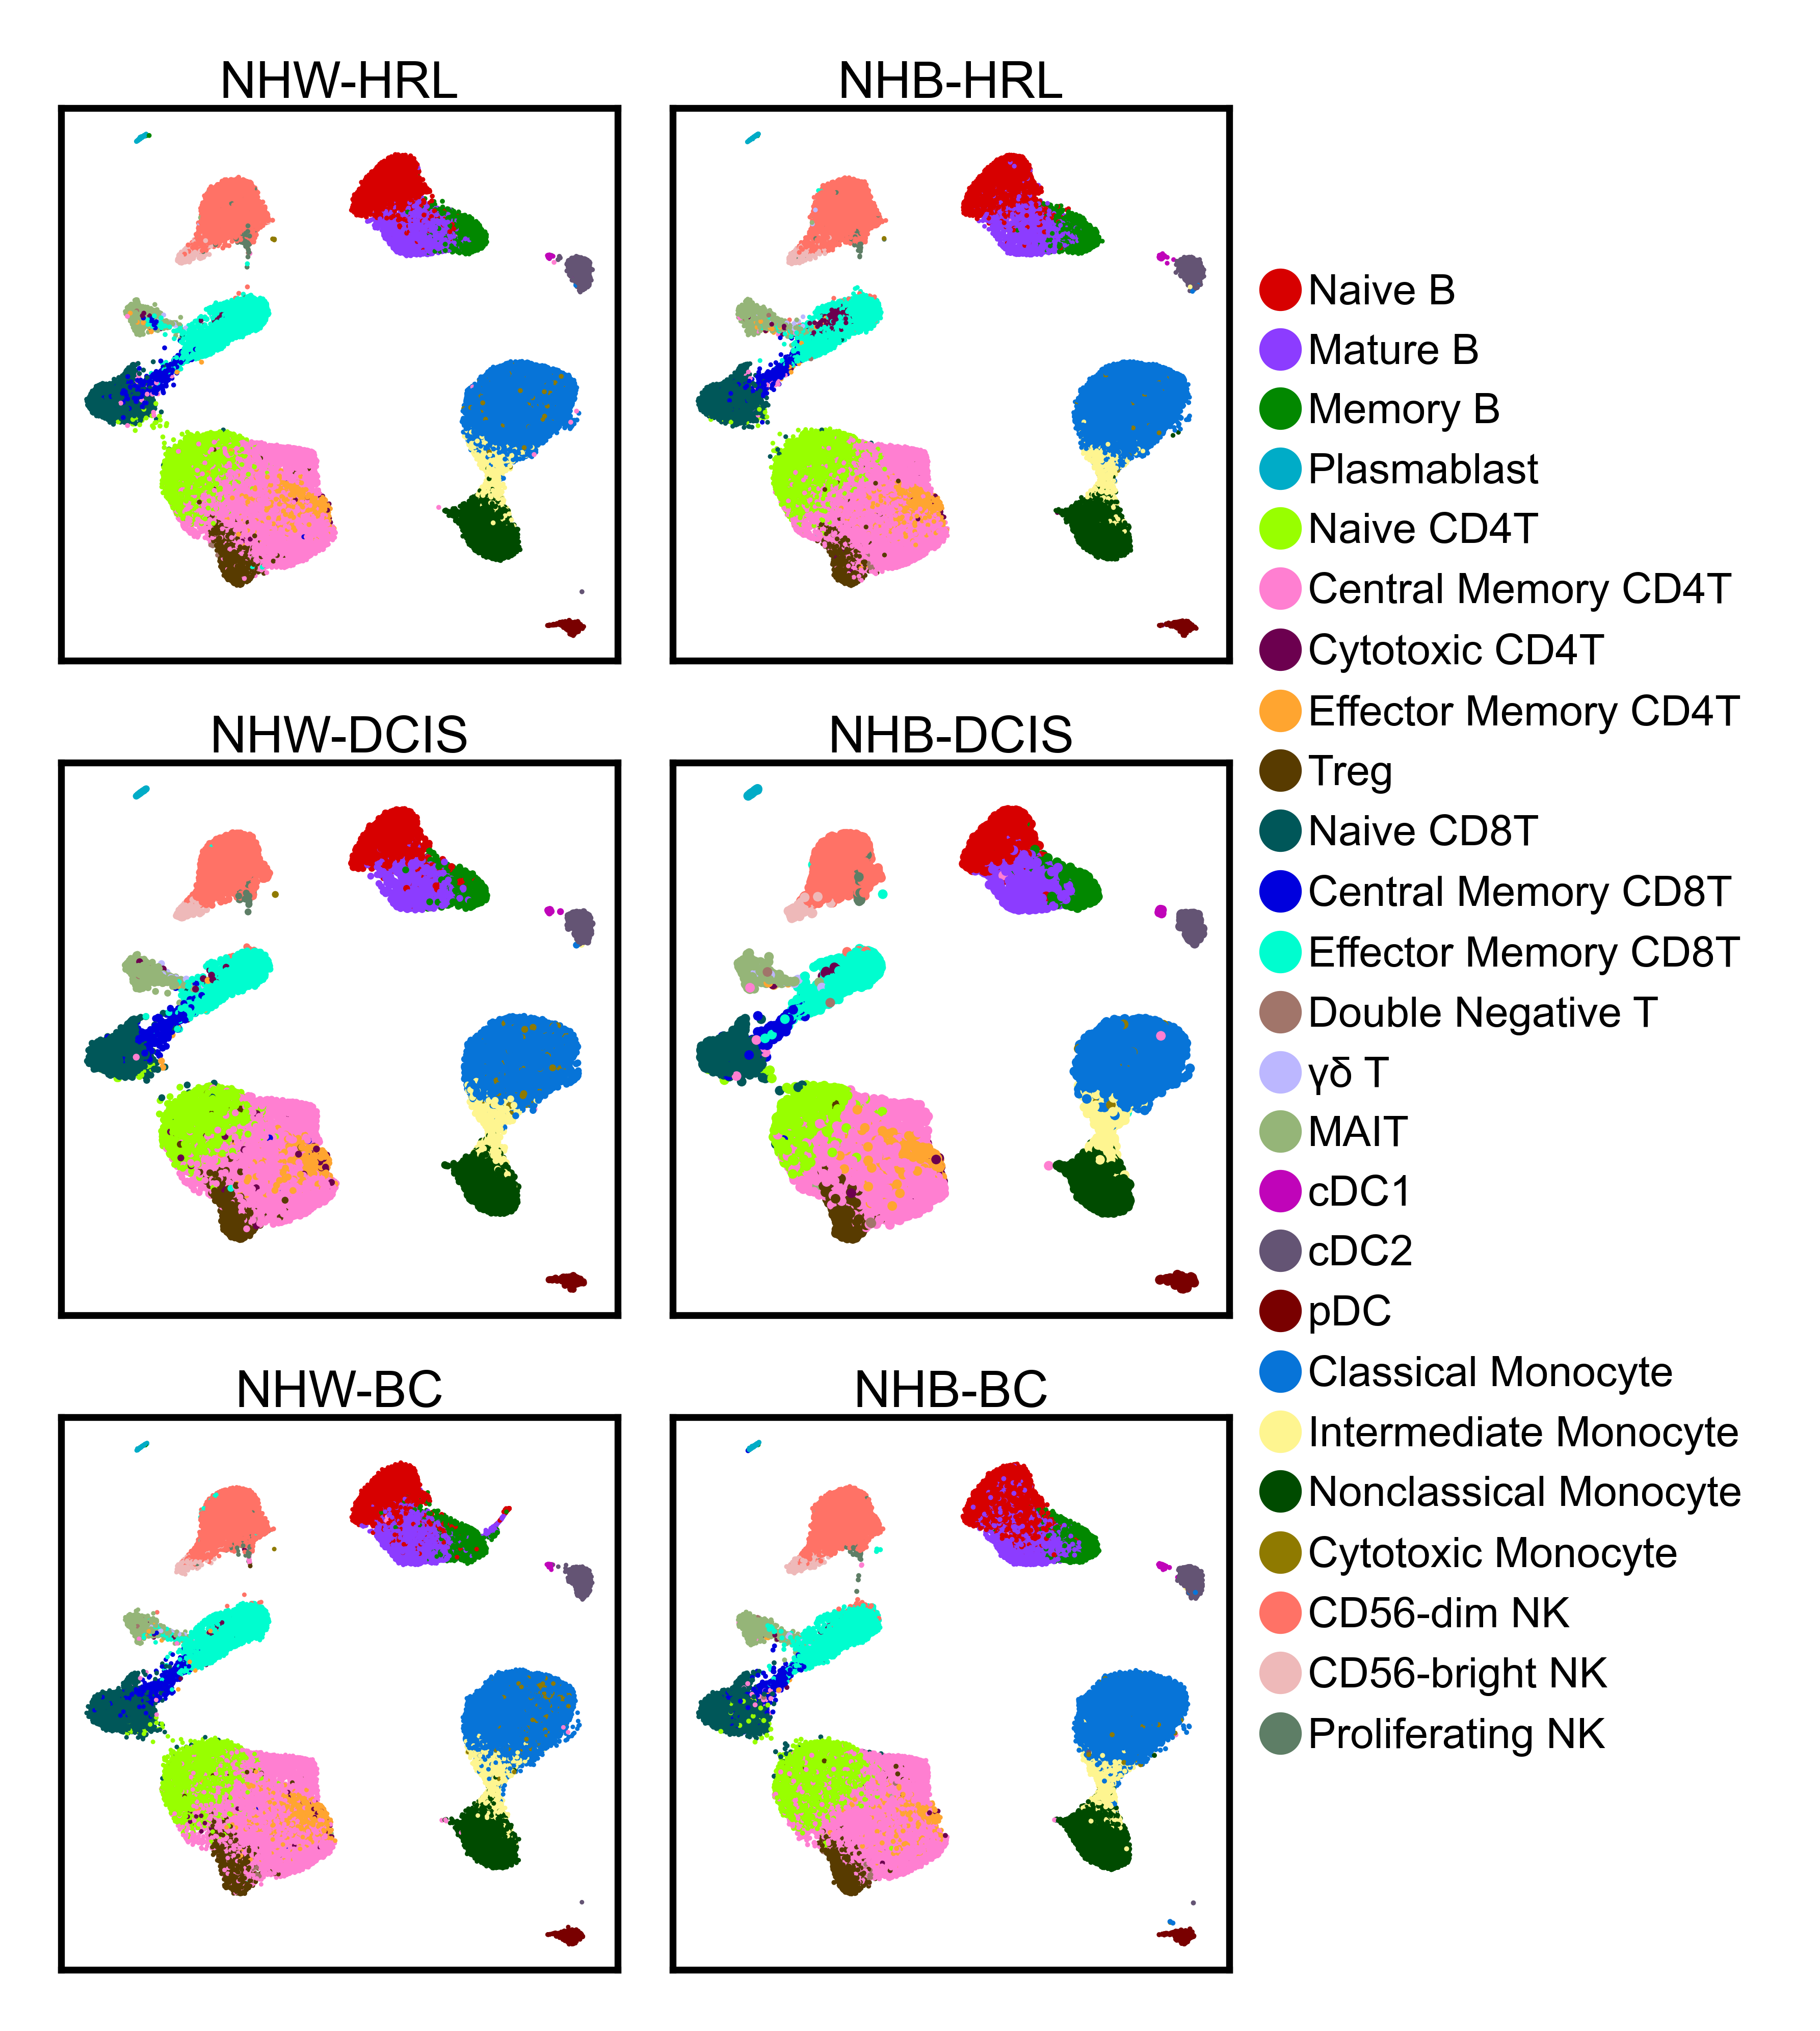

In [68]:
split_umap(dat, 
           'race_stage',
           color=['celltype_level3'],
           palette=celltype_palette,
           save="plots/FigureS1/umap_split.svg"
          )

# QC metrics

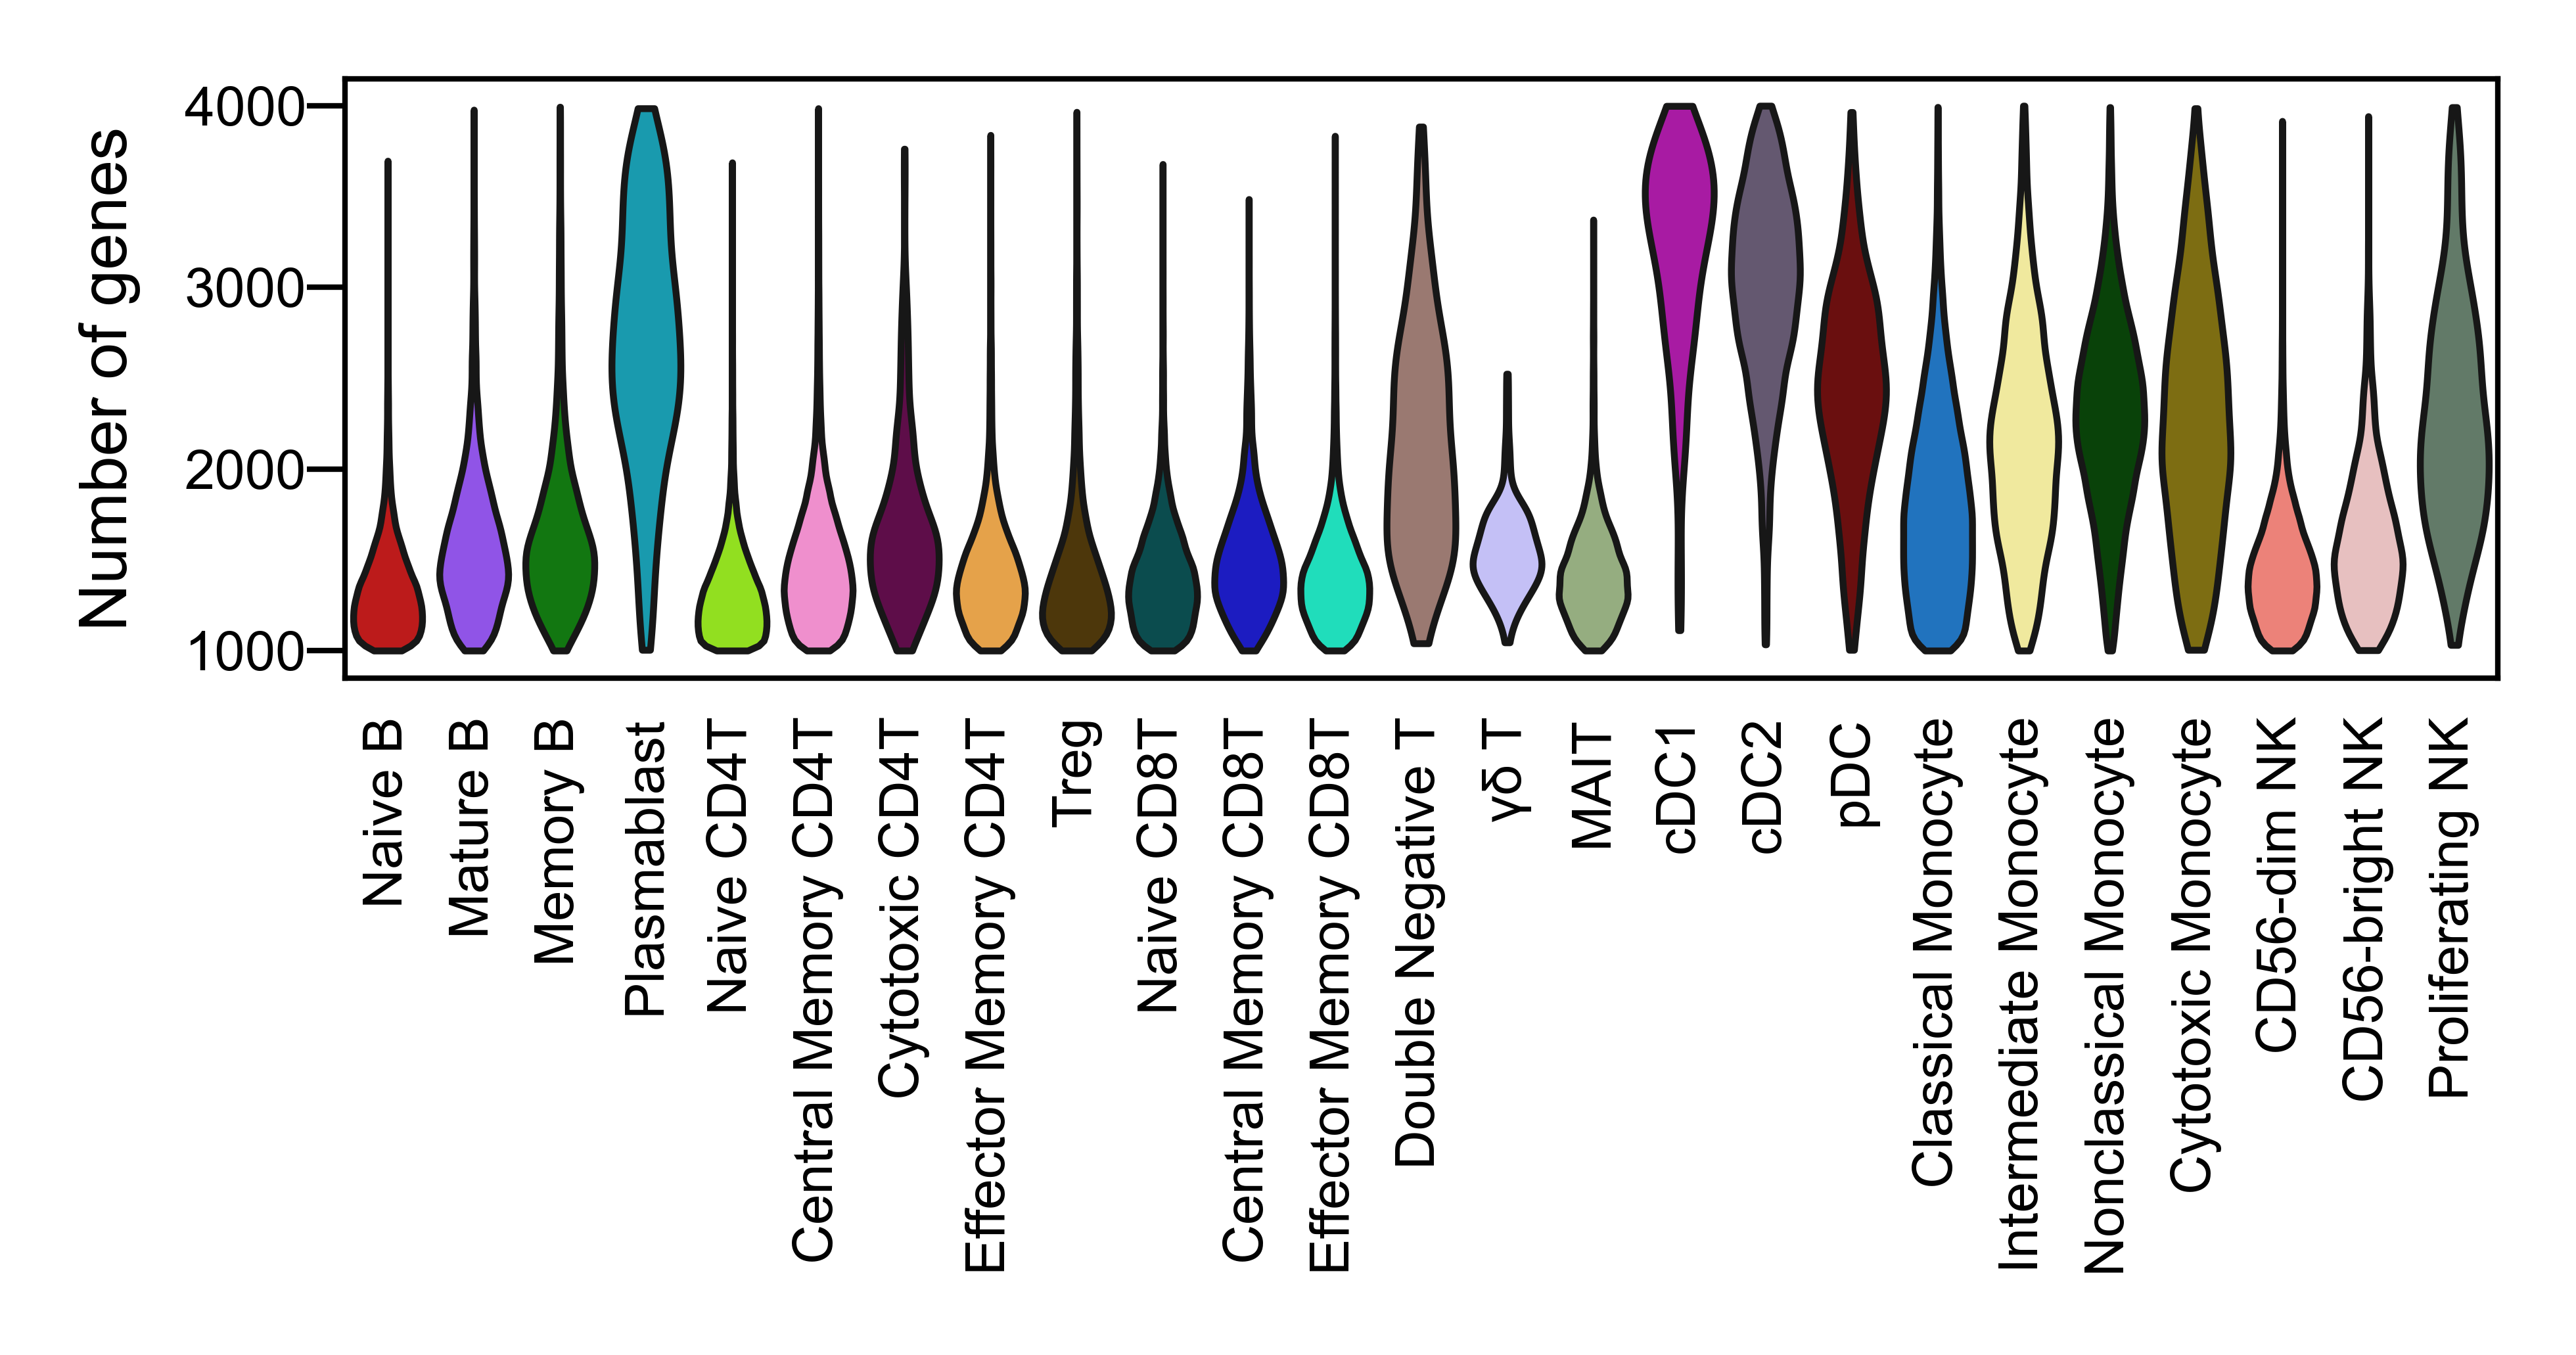

In [73]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['nFeature_RNA'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Number of genes',
    rotation=90,
    ax=ax,
    save='qc_NumGenes.svg'
)


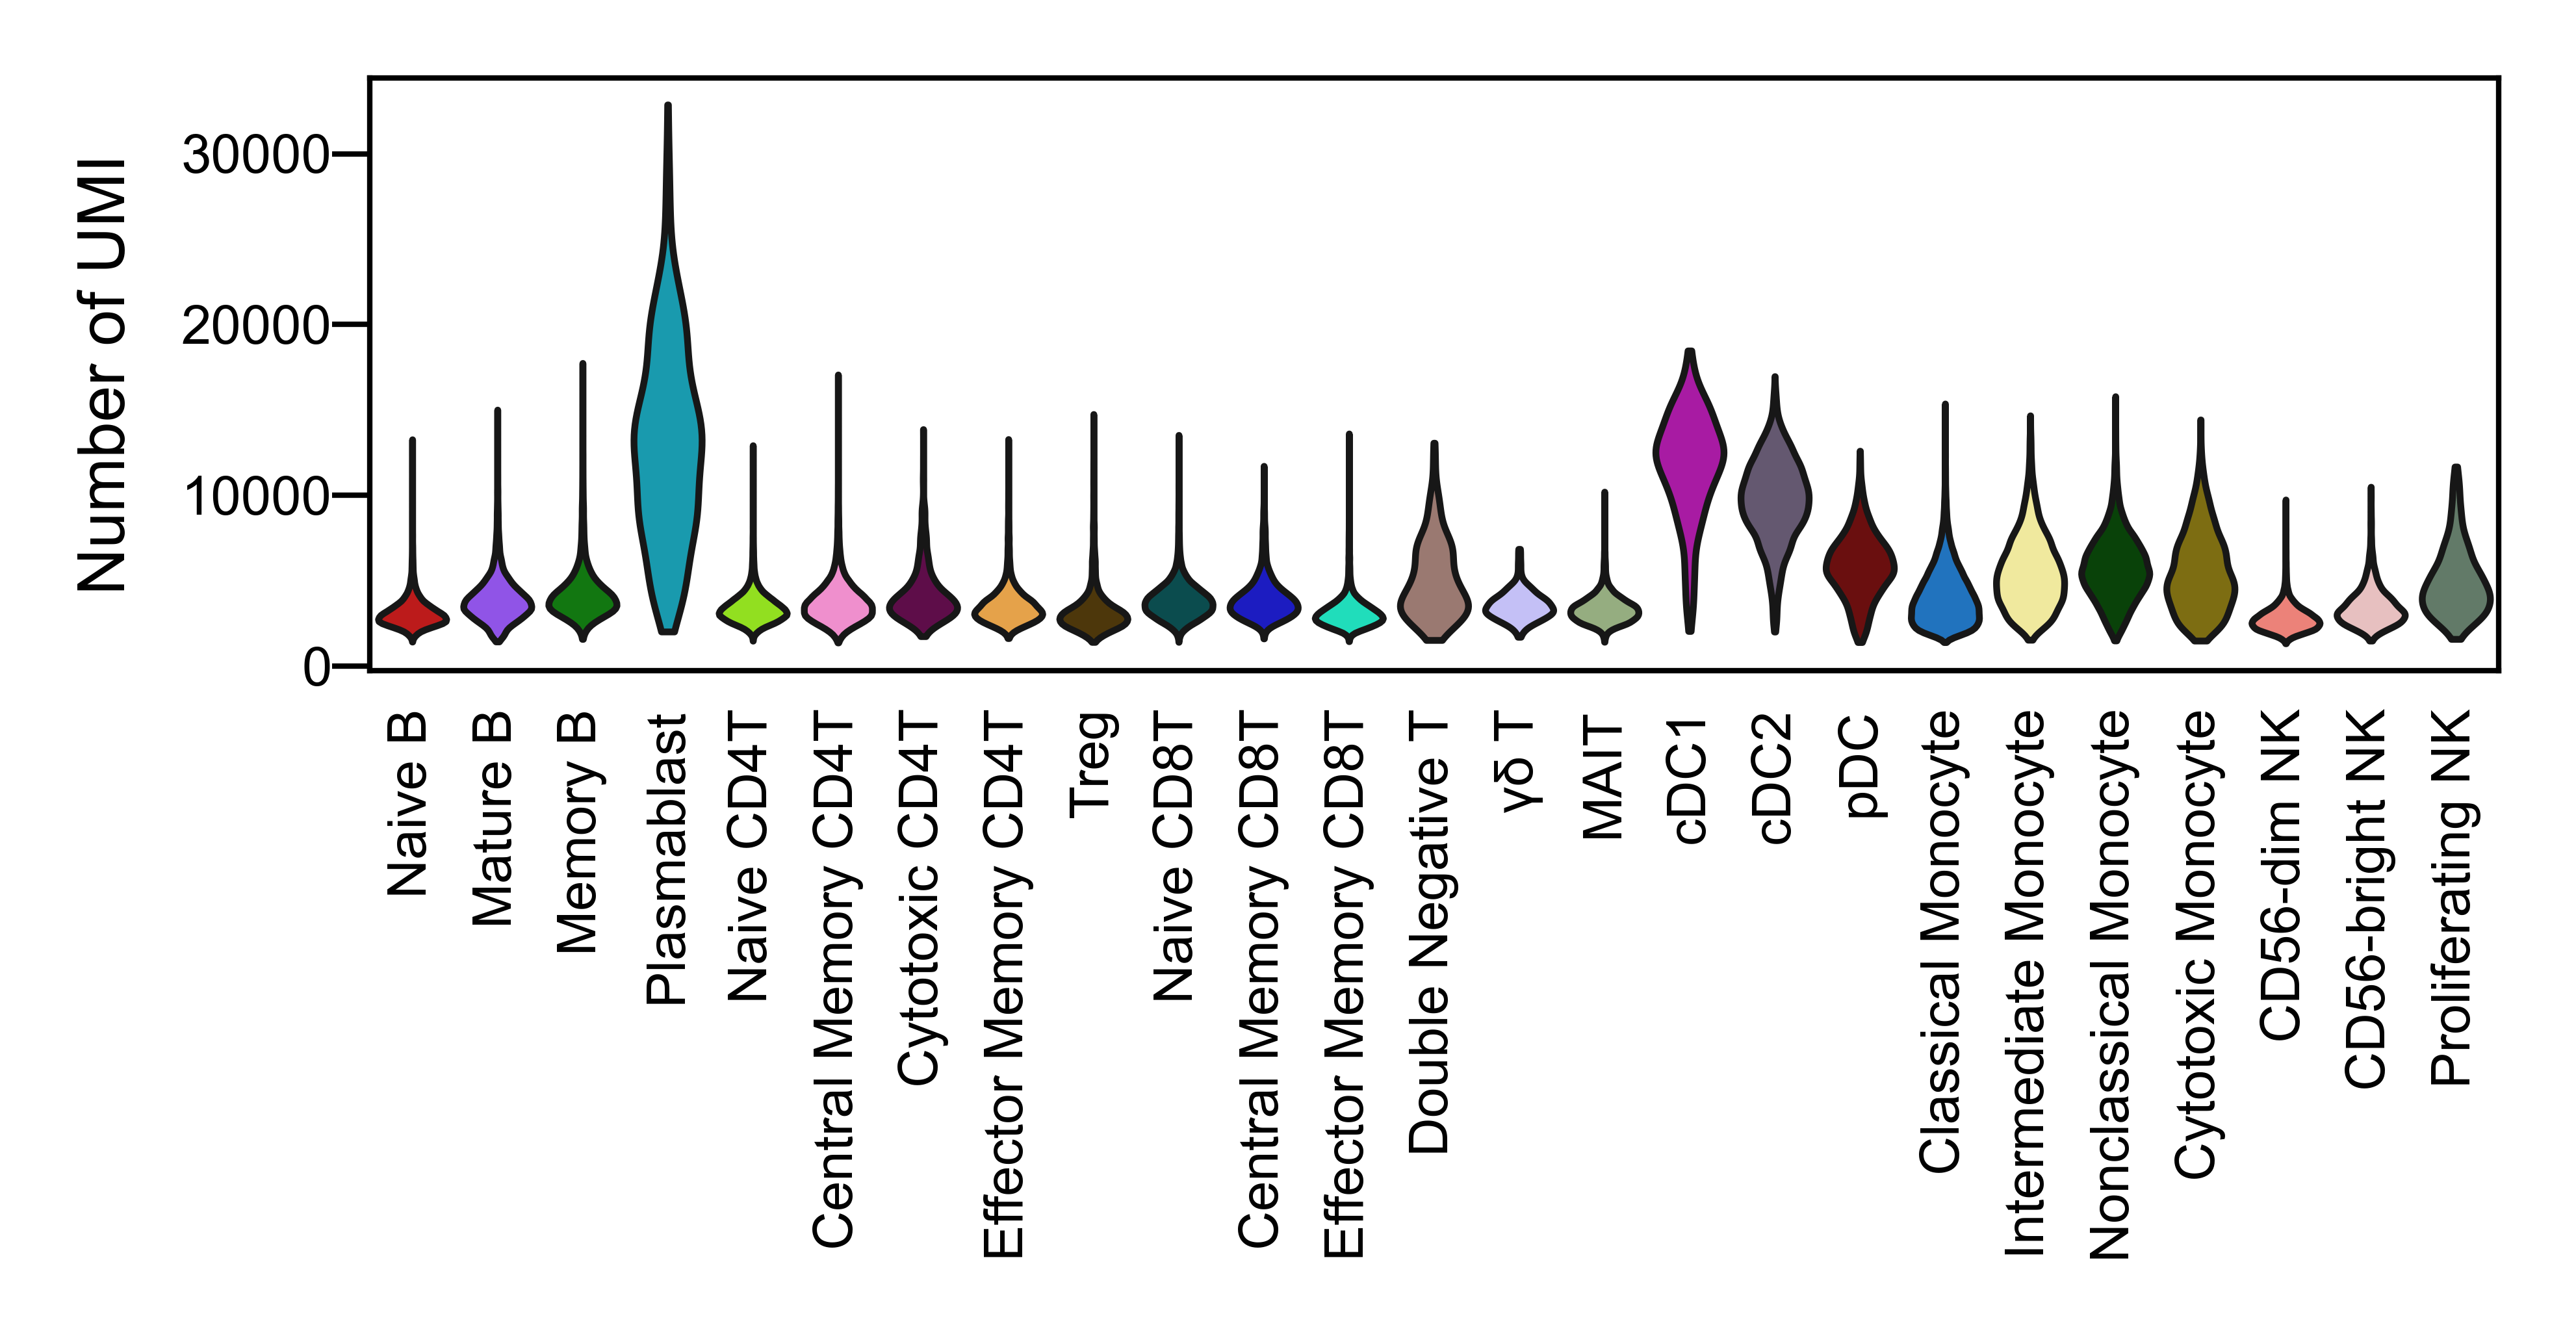

In [74]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['nCount_RNA'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Number of UMI',
    rotation=90,
    ax=ax,
    save='qc_NumUMI.svg'
)


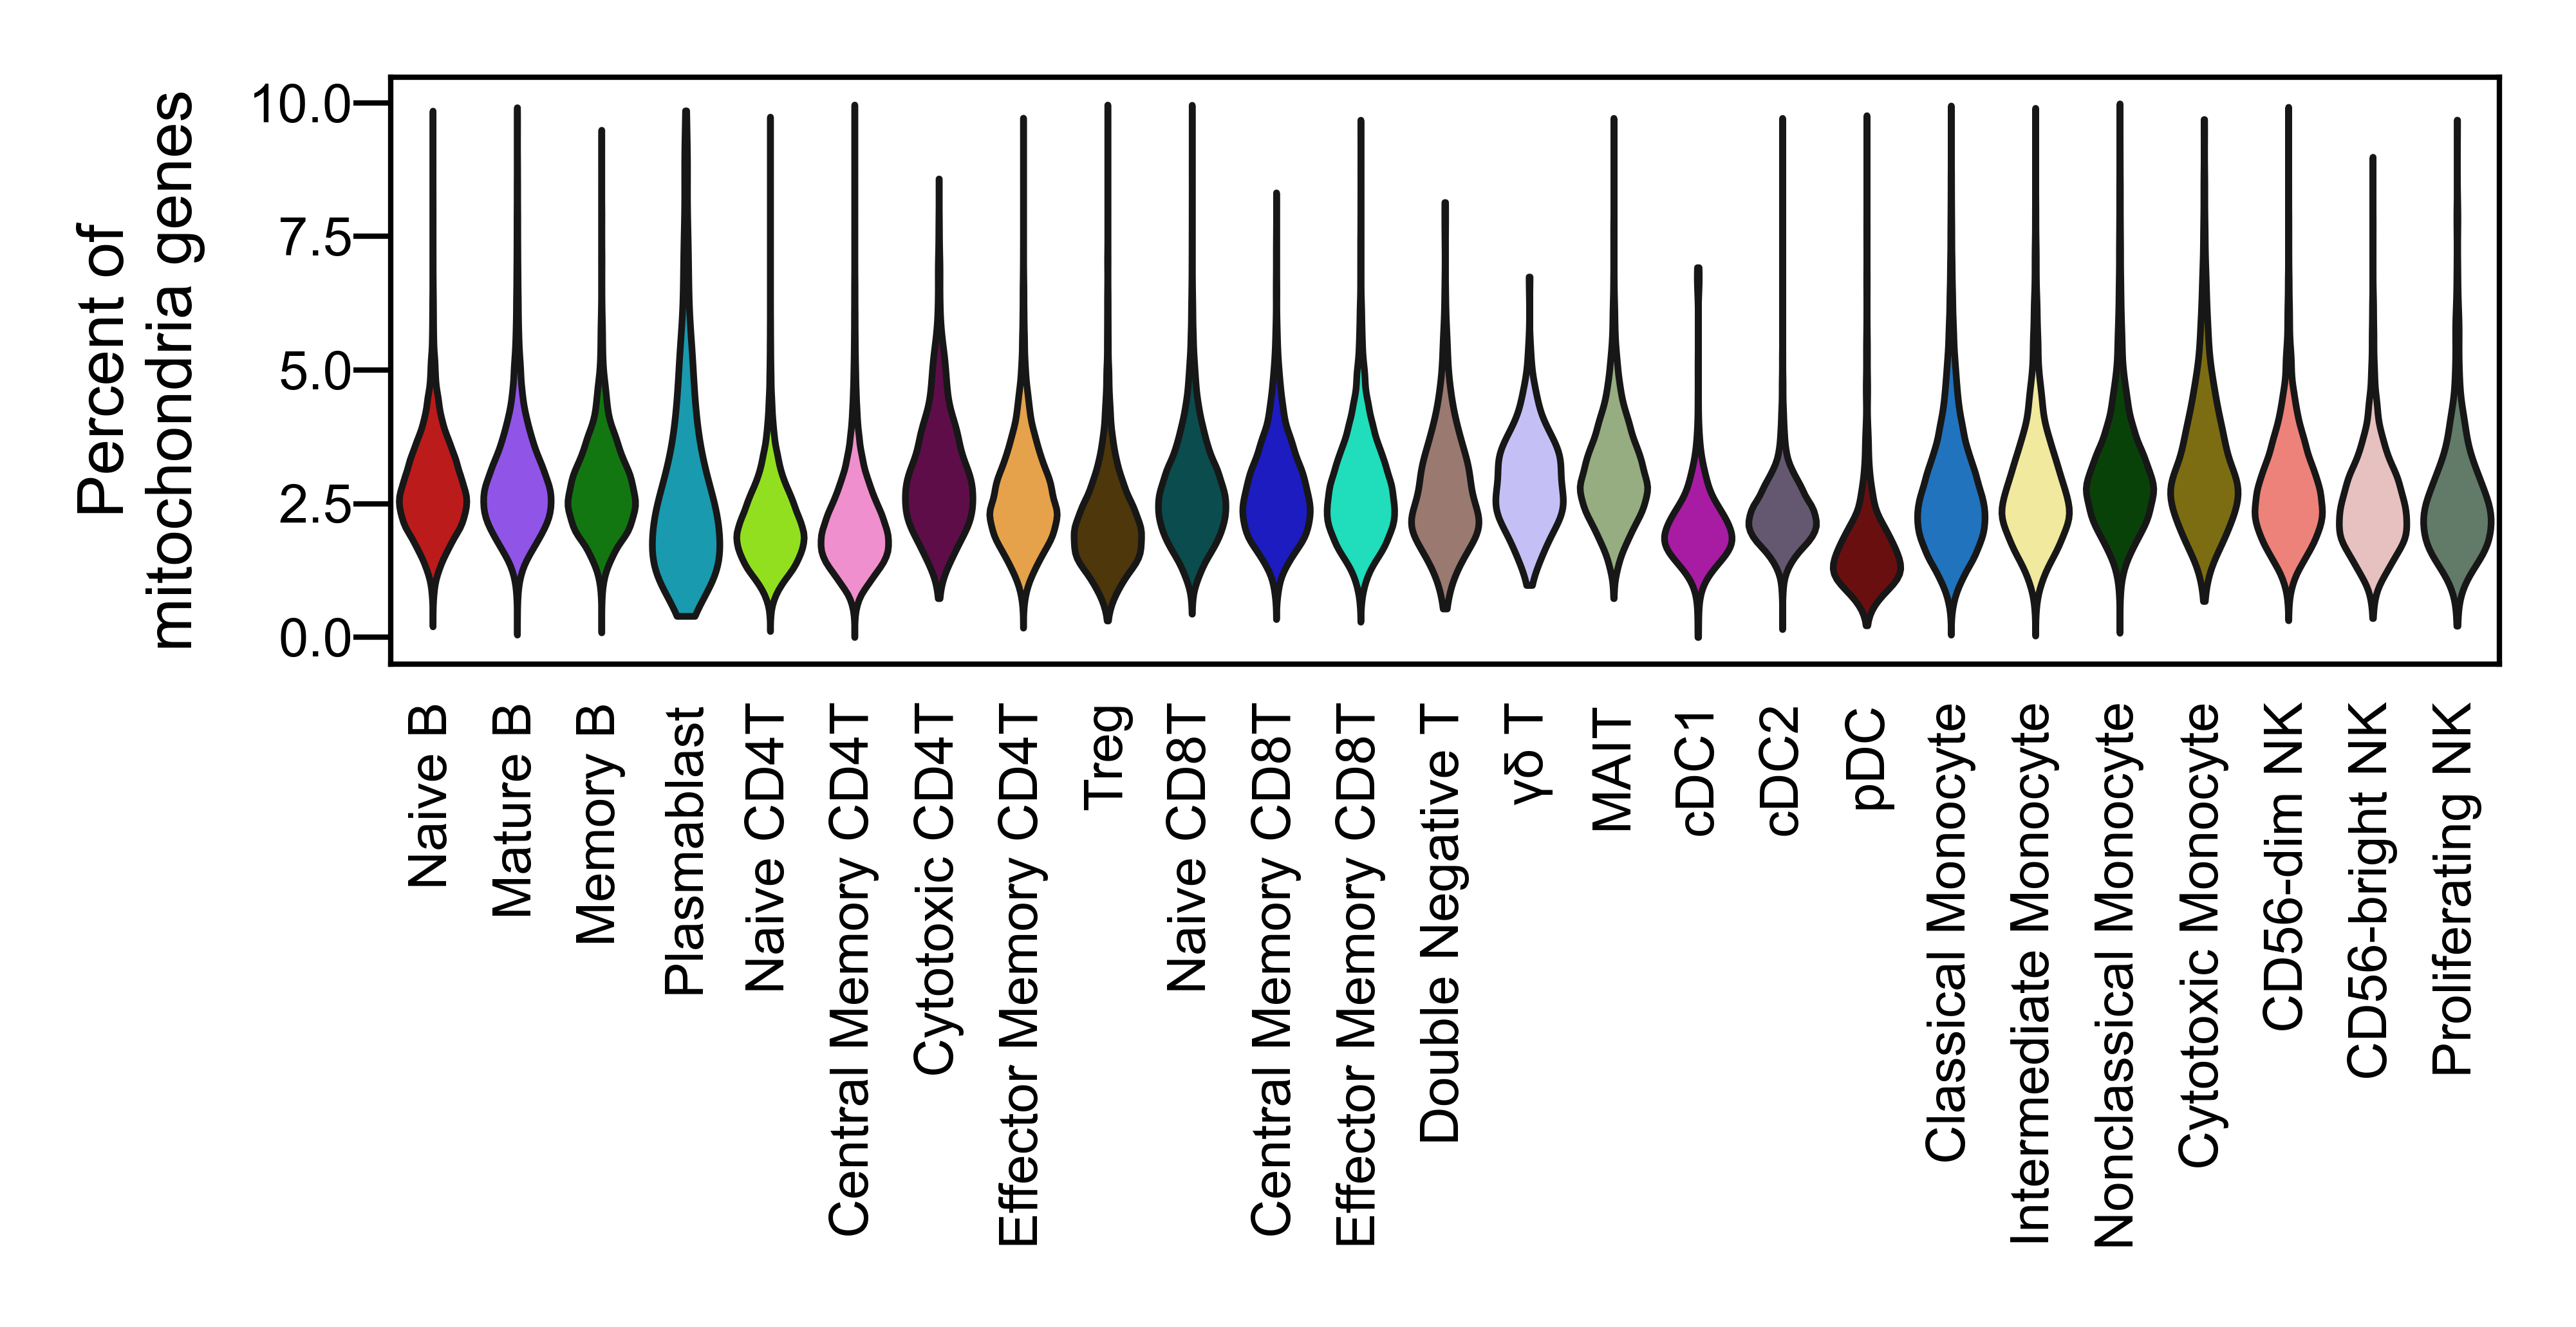

In [75]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['percent.mt'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Percent of\nmitochondria genes',
    rotation=90,
    ax=ax,
    save='qc_Mtpct.svg'
)


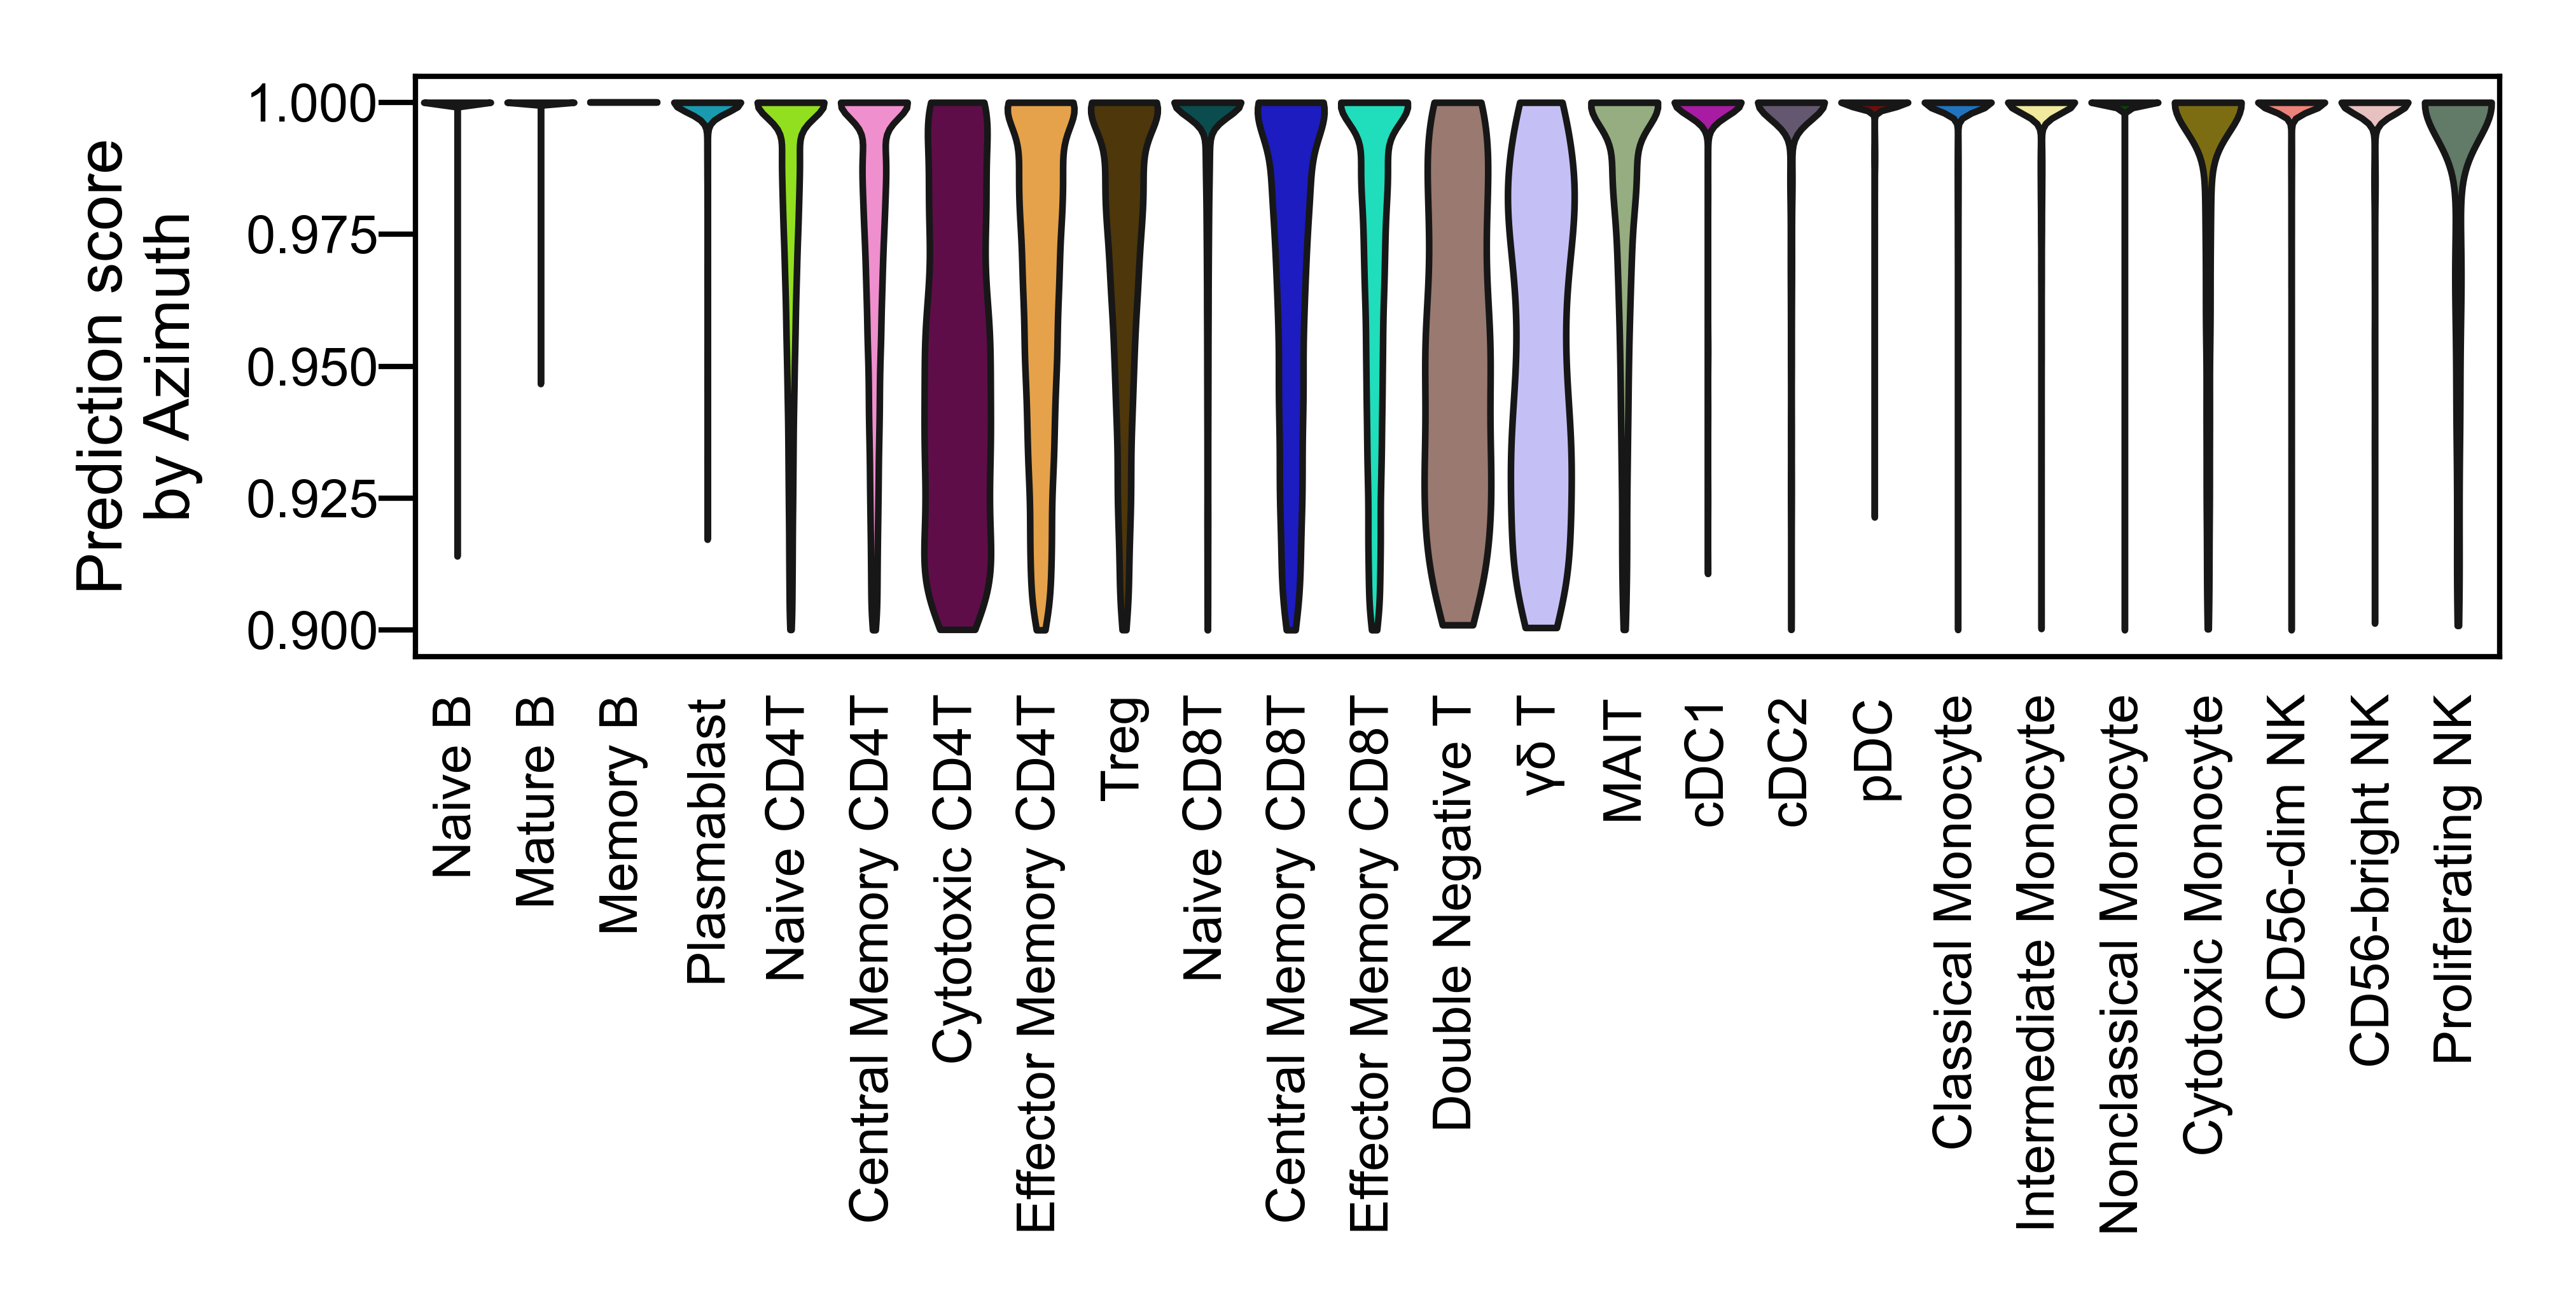

In [76]:
sc.settings.figdir = "plots/S1"

fig, ax = plt.subplots(figsize=(3.5, 1))

sc.pl.violin(
    dat,
    keys=['predicted.celltype.l1.score'],
    groupby='celltype_level3',
    hue = 'celltype_level3',
    palette=palette,
    stripplot=False,
    legend=False,
    xlabel='',
    ylabel='Prediction score\nby Azimuth',
    rotation=90,
    ax=ax,
    save='qc_azimuthScoreL1.svg'
)


# Key protein markers

In [35]:
impadt = pd.read_csv('data/03_cleandata/ft_all_impADT.csv', index_col=0)

impadt.columns = [f'impADT-{x}' for x in impadt.columns]
impadt

,impADT-CD39,impADT-Rat-IgG1-1,impADT-CD107a,impADT-CD62P,impADT-TCR-2,impADT-CD30,impADT-CD31,impADT-CD34,impADT-CD35,impADT-CD36,...,impADT-CD169,impADT-CD28,impADT-CD161,impADT-CD163,impADT-CD138-1,impADT-CD164,impADT-CD138-2,impADT-CD144,impADT-CD202b,impADT-CD11c
Pool137_10_AAACCTGAGACTCGGA-1,0.534771,0.785664,1.065888,2.486620,1.455330,0.288762,2.010069,0.543328,2.193929,0.091107,...,0.178707,2.075897,0.157420,0.395004,0.746080,0.266822,0.714414,0.703357,0.794421,0.816402
Pool137_10_AAACCTGAGATCTGCT-1,1.449415,0.667198,1.409613,3.622773,0.756409,0.276608,3.843209,0.701777,2.597695,0.575529,...,0.435918,1.027539,0.154405,0.470037,0.452024,0.488064,0.660572,0.507108,0.594781,1.957562
Pool137_10_AAACCTGAGATTACCC-1,0.452265,0.744363,0.950950,2.527489,1.274952,0.350221,2.292906,0.577347,2.148938,0.111531,...,0.235422,1.921119,0.193224,0.305376,0.644874,0.308330,0.638812,0.708355,0.717815,0.808716
Pool137_10_AAACCTGAGCTGCGAA-1,0.457184,0.743687,1.007076,2.489951,1.504251,0.353372,1.928150,0.587430,2.122775,0.118000,...,0.216452,2.083942,0.217496,0.381886,0.581419,0.211308,0.686135,0.668243,0.729290,0.903699
Pool137_10_AAACCTGAGGACACCA-1,1.333606,0.514865,1.641695,3.931263,0.728445,0.187504,3.775454,0.703609,2.658446,0.691417,...,0.397310,0.917504,0.166297,0.450487,0.386663,0.559608,0.630211,0.501299,0.550563,2.138054
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1.282291,0.748149,1.338984,3.064777,0.747717,0.329519,3.144872,0.701284,4.059995,0.752640,...,0.609118,1.075461,0.181407,0.460948,0.656513,0.366761,0.802404,0.660312,0.745983,1.922274
Pool138_9_TTTGTCATCCTAGGGC-1,0.349624,0.709147,1.003383,2.520453,1.337860,0.178123,1.757185,0.553130,2.815921,0.133724,...,0.328057,2.326010,0.310319,0.388375,0.594377,0.282331,0.778680,0.771170,0.787437,0.856449
Pool138_9_TTTGTCATCGCACTCT-1,0.486551,0.747766,0.945113,2.519550,1.570202,0.306416,1.920877,0.571780,2.120506,0.148358,...,0.197388,2.130674,0.197334,0.373094,0.584165,0.265373,0.665075,0.731853,0.697750,0.870280
Pool138_9_TTTGTCATCTAACTGG-1,0.403886,0.751390,0.949030,2.523064,1.383994,0.272842,1.826066,0.540308,2.226121,0.136343,...,0.200529,2.248959,0.250389,0.354785,0.599786,0.308921,0.601553,0.735475,0.807407,0.818152


In [36]:
dat.obs.head(3)

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,Phase,celltype_level3,sampleid,batch,group,race,age,diabetes,obesity,race_stage
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,G1,Naive CD4T,1-H,1,HRL,NHW,62.3,N,N,NHW-HRL
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,S,Nonclassical Monocyte,1-H,1,HRL,NHW,62.3,N,N,NHW-HRL
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,S,Naive CD8T,1-H,1,HRL,NHW,62.3,N,N,NHW-HRL


In [37]:
# Example: Ensure the impadt index is of string type to match dat.obs_names
impadt.index = impadt.index.astype(str)
dat.obs.index = dat.obs.index.astype(str)

# Subset impadt to only cells in dat
impadt_sub = impadt.loc[dat.obs_names.intersection(impadt.index)]

# Make sure order matches dat.obs_names
impadt_sub = impadt_sub.reindex(dat.obs_names)

# Add as obs columns (will add each protein as a new column in .obs)
dat.obs = pd.concat([dat.obs, impadt_sub], axis=1)

# Now each protein marker is accessible via dat.obs['CD19'], dat.obs['CD20'], etc.

In [38]:
# Panel/grid setup

channels = [
    'CD19','CD20','CD21','CD22','CD38-1',
    'CD3-1','CD4-1','CD8','TCR-V-2','CD161',
    'CD1c','CD141','CD123','CD303','CD304',
    'CD64','CD14','CD16','CD335','CD56-1'
]
ncols = 5
nrows = int(np.ceil(len(channels) / ncols))
panel_width = 2   # inches per plot (adjust as needed)
panel_height = 2  # inches per plot
figsize = (panel_width * ncols, panel_height * nrows)
sc.set_figure_params(figsize=figsize)

major_celltype_palette = {
    'B':    'Blues',
    'T':    'Oranges',
    'DC':   'Greens',
    'Mono': 'Reds',
    'NK':   'Purples',
}
channel2celltype = {
    'CD19': 'B', 'CD20': 'B', 'CD21': 'B', 'CD22': 'B', 'CD38-1': 'B',
    'CD3-1': 'T', 'CD4-1': 'T', 'CD8': 'T', 'TCR-V-2': 'T', 'CD161': 'T',
    'CD1c': 'DC', 'CD141': 'DC', 'CD123': 'DC', 'CD303': 'DC', 'CD304': 'DC',
    'CD64': 'Mono', 'CD14': 'Mono',
    'CD16': 'NK', 'CD335': 'NK', 'CD56-1': 'NK'
}

fig, axs = plt.subplots(figsize=figsize, 
                        ncols=ncols, nrows=nrows,
                        gridspec_kw={'wspace': 0.3, 'hspace': 0.3}  # <-- increased spacing
                       )
axs = axs.flatten()

for idx, ch in enumerate(channels):
    ax = axs[idx]
    sc.pl.umap(
        dat,
        color=f'impADT-{ch}',
        show=False,
        title=ch,  # Just the channel name for the subplot
        legend_loc=None,  # Hide legend, show colorbar   
        frameon=False,
        cmap=major_celltype_palette[channel2celltype[ch]],
        ax=ax
    )
    ax.tick_params(axis='both', labelsize=6, pad=0)
    ax.title.set_fontsize(15)

# ---- ADJUST COLORBAR FONT SIZES ----
for child_ax in fig.axes:
    if hasattr(child_ax, 'get_ylabel') and child_ax.get_ylabel() != '':
        child_ax.tick_params(labelsize=5)
        child_ax.yaxis.label.set_size(5)
        # For horizontal colorbars, use: child_ax.xaxis.label.set_size(5)

fig.savefig('plots/FigureS1/impADT_mainCelltypes.svg', bbox_inches='tight', dpi=600)
plt.close(fig)

# Major cell type color legend

/tmp/ipykernel_4003074/4074073658.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color = cm.get_cmap(palette[lab])(cmap_pos)


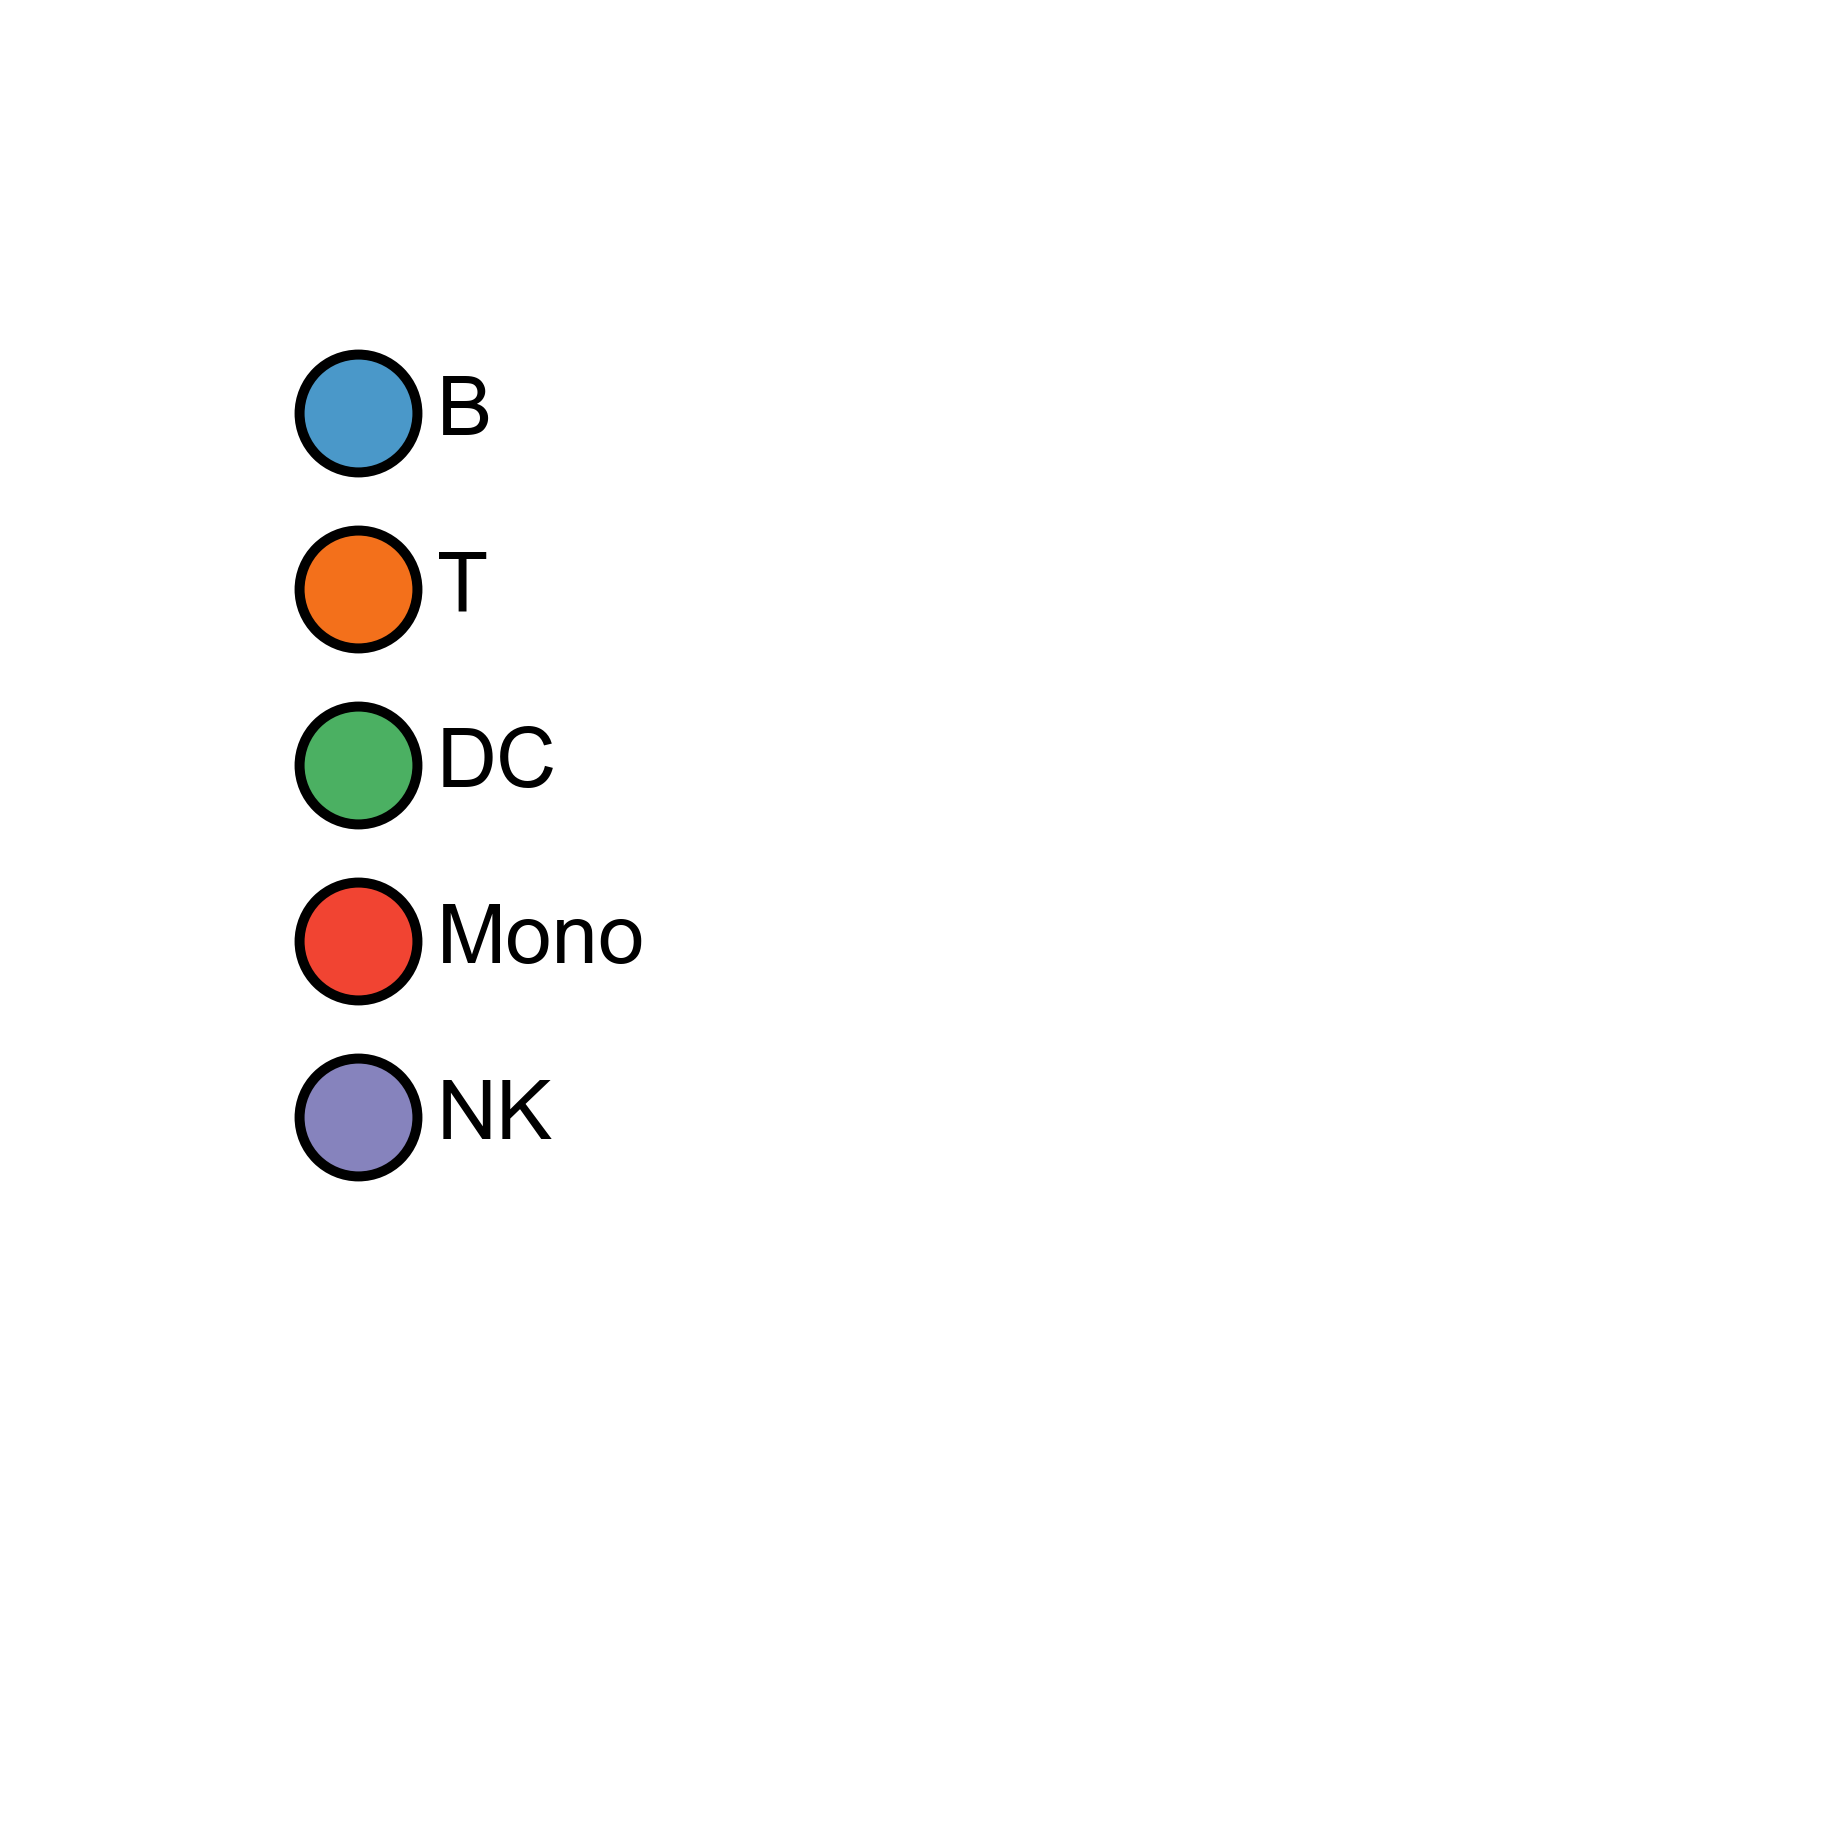

In [20]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

major_celltype_palette = {
    'B':    'Blues',
    'T':    'Oranges',
    'DC':   'Greens',
    'Mono': 'Reds',
    'NK':   'Purples',
}

def legend_column(palette, filename="major_celltype_legend.svg",
                  dot_size=50, font_size=5, cmap_pos=0.6, gap=0.1, step=0.3):
    """
    One row per cell type (vertical legend).
    """
    labels = list(palette.keys())
    n = len(labels)

    # Figure height tuned to number of entries
    fig_w = 1.5
    fig_h = n * step
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))

    x = 0.3  # left margin
    y0 = 0.8  # starting top position
    for i, lab in enumerate(labels):
        y = y0 + (n - 1 - i) * step  # plot from top to bottom
        color = cm.get_cmap(palette[lab])(cmap_pos)

        # dot
        ax.scatter([x], [y], s=dot_size, c=[color], edgecolor='black', linewidth=0.6)

        # text to the right
        ax.text(x + gap, y, lab, va='center', ha='left', fontsize=font_size)

    # tidy like a legend
    ax.set_xlim(0, 2)
    ax.set_ylim(-0.2, y0 + (n - 1) * step + 0.5)
    ax.axis('off')

    plt.tight_layout()
    plt.savefig(filename, format="svg")
    plt.show()

# run
legend_column(major_celltype_palette, filename="plots/LegendShared/major_celltype_palette.svg")